<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/kmeans_hierarchical_card_fraud_lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 6
## Метод k-середніх. Ієрархічна кластеризація

**Мета:** реалізувати алгоритми k-середніх та ієрархічної кластеризації на датасеті платіжних транзакцій, порівняти їх та дослідити, як якість («точність») кластеризації залежить від параметрів даних.

**Завдання:** виконати реалізацію алгоритмів k-середніх та ієрархічної кластеризації на одному з датасетів Kaggle (розділ *security*). Дослідити залежність точності методу від параметрів даних.

**Датасет:** Credit Card Fraud Detection Dataset 2023 ([Kaggle: nelgiriyewithana/credit-card-fraud-detection-dataset-2023](https://www.kaggle.com/datasets/nelgiriyewithana/credit-card-fraud-detection-dataset-2023)) — файл `creditcard_2023.csv`, 568 630 транзакцій банківських карток: службовий номер `id`, 28 анонімізованих ознак `V1`–`V28`, сума `Amount` та мітка `Class` (0 — легальна, 1 — шахрайська транзакція). Кластеризація — навчання без вчителя, тому мітка алгоритмам не передається й використовується лише для оцінки результату.

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних та метрики якості кластеризації
4. Реалізація алгоритму k-середніх (та k-медіан)
5. Реалізація ієрархічної (агломеративної) кластеризації
6. Базові моделі
7. Залежність точності від параметрів даних: масштабування, набір ознак, шумові ознаки, викиди, дисбаланс класів, кількість кластерів, ініціалізація центрів, тип зв'язку та метрика, дендрограма й поріг відстані, розмір вибірки та час роботи
8. Підсумкова модель на всьому датасеті
9. Порівняння методів
10. Переваги та недоліки методів
11. Загальні висновки

## 0. Імпорт бібліотек

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, roc_auc_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Файл береться з поточної папки; якщо його там немає — завантажується з Kaggle через `kagglehub`; якщо й це не вдалося — з'явиться вікно для ручного завантаження CSV (файл ≈ 325 МБ, завантаження може тривати кілька хвилин).

In [2]:
FILE_NAME = "creditcard_2023.csv"

def find_dataset():
    if os.path.exists(FILE_NAME):
        return FILE_NAME
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        folder = kagglehub.dataset_download("nelgiriyewithana/credit-card-fraud-detection-dataset-2023")
        csv_files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        csv_files.sort(key=lambda p: os.path.basename(p) != FILE_NAME)  # потрібний файл — першим
        if csv_files:
            return csv_files[0]
    except Exception as e:
        print("Автозавантаження з Kaggle не вдалося:", e)
    from google.colab import files
    print(f"Завантажте файл {FILE_NAME} вручну:")
    return next(iter(files.upload()))

raw = pd.read_csv(find_dataset())
print("Датасет завантажено:", raw.shape)

100%|██████████| 143M/143M [00:08<00:00, 17.5MB/s]

Extracting files...


Датасет завантажено: (568630, 31)


## 2. Первинний аналіз даних
Дивимось на структуру таблиці, пропуски, дублікати, баланс класів і розподіли ознак; перевіряємо, які ознаки пов'язані з міткою `Class` (мітка потрібна лише для аналізу та оцінки результату — алгоритми кластеризації її не бачать).

In [3]:
V = [f"V{i}" for i in range(1, 29)]
print("Розмір таблиці:", raw.shape)
print("Пропусків (NaN):", int(raw.isna().sum().sum()), "| дублікатів (без id):", int(raw.drop(columns="id").duplicated().sum()))
print("Розподіл класів:", raw["Class"].value_counts().to_dict())
print("V1–V28: середнє ≈ {:.3f}, стандартне відхилення ≈ {:.3f}".format(raw[V].mean().mean(), raw[V].std().mean()))
print("Amount: min = {:.0f}, max = {:.0f}, середнє = {:.0f}, стандартне відхилення = {:.0f}".format(
    raw["Amount"].min(), raw["Amount"].max(), raw["Amount"].mean(), raw["Amount"].std()))
print("Ознаки з найважчими «хвостами» (ексцес):", raw[V].kurt().sort_values(ascending=False).head(5).round(0).to_dict())
raw.sample(5, random_state=RANDOM_STATE)

Розмір таблиці: (568630, 31)
Пропусків (NaN): 0 | дублікатів (без id): 1
Розподіл класів: {0: 284315, 1: 284315}
V1–V28: середнє ≈ -0.000, стандартне відхилення ≈ 1.000
Amount: min = 50, max = 24040, середнє = 12042, стандартне відхилення = 6920
Ознаки з найважчими «хвостами» (ексцес): {'V7': 4018.0, 'V27': 301.0, 'V28': 162.0, 'V20': 130.0, 'V23': 65.0}


,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
437378,437378,0.420468,-0.070194,-0.569266,0.191673,-0.009607,0.426903,-0.356728,0.096143,0.077806,...,0.134969,0.070433,0.047770,-0.851622,0.102876,-0.375436,0.820807,0.665983,8633.18,1
504222,504222,-0.238944,0.250929,-0.374408,0.152938,-0.105008,-0.039028,-0.293004,0.133771,-0.591631,...,0.192405,0.289441,-0.255187,-0.817462,0.308284,1.582688,0.574425,0.478489,12299.55,1
4794,4794,-0.117796,-0.147961,2.130455,-0.325762,0.325616,0.271351,0.772625,-0.244342,1.240012,...,-0.271739,-0.404654,-0.121235,0.857659,0.541920,0.756534,-0.238177,-0.403038,5215.87,0
388411,388411,-0.855315,0.137014,-0.628116,0.613733,-0.643573,-0.664283,-0.880040,0.466586,-1.045508,...,0.405505,0.167560,0.446262,-0.205976,0.492582,0.658619,1.609128,-0.025592,19282.98,1
424512,424512,0.257686,0.035247,-0.203112,0.506745,-0.242235,-0.192608,-0.289297,0.044488,-0.396122,...,0.162191,0.165912,-0.181999,0.331451,1.043095,0.029799,0.643273,0.736723,19114.27,1


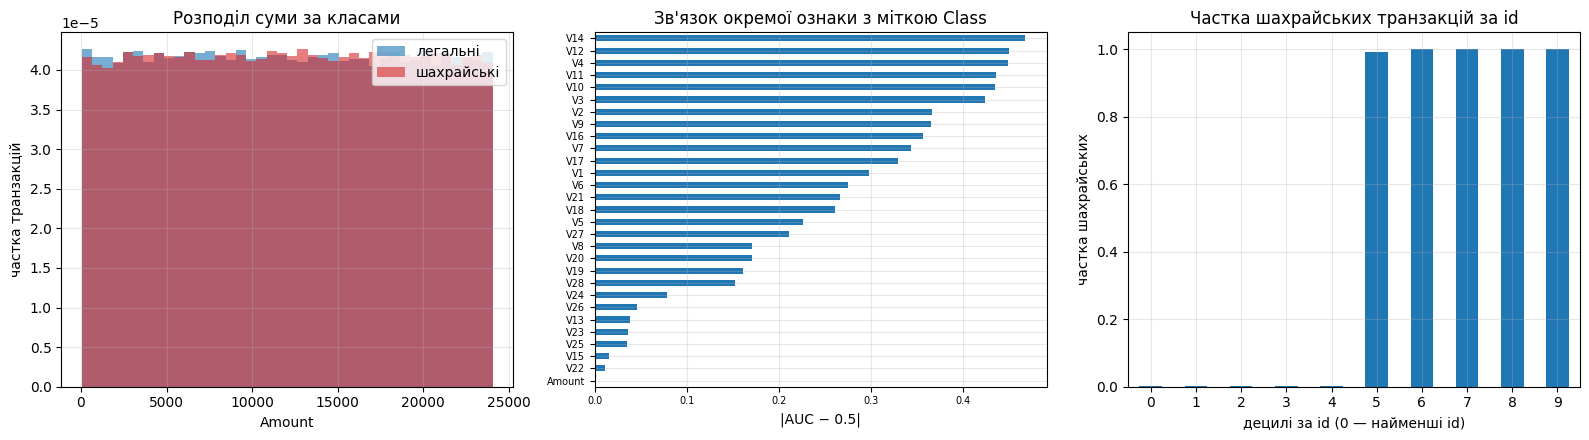

Найінформативніші ознаки: {'V14': 0.468, 'V12': 0.45, 'V4': 0.45, 'V11': 0.436, 'V10': 0.435, 'V3': 0.424}
AUC колонки id щодо мітки: 0.999


In [4]:
# впорядкування ознак за зв'язком з міткою: |AUC − 0.5| для кожної ознаки окремо.
# Використовується лише для аналізу та для експериментів 7.2–7.3 (алгоритмам кластеризації мітки не передаються)
auc = pd.Series({c: roc_auc_score(raw["Class"], raw[c]) for c in V + ["Amount"]})
INFORMATIVE = (auc - 0.5).abs().sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for lab, color, name in [(0, "tab:blue", "легальні"), (1, "tab:red", "шахрайські")]:
    ax[0].hist(raw.loc[raw["Class"] == lab, "Amount"], bins=40, alpha=0.6, color=color, label=name, density=True)
ax[0].set_xlabel("Amount"); ax[0].set_ylabel("частка транзакцій"); ax[0].set_title("Розподіл суми за класами"); ax[0].legend()

top = INFORMATIVE.sort_values()
top.plot.barh(ax=ax[1], color=["tab:red" if c == "Amount" else "tab:blue" for c in top.index], fontsize=7)
ax[1].set_xlabel("|AUC − 0.5|"); ax[1].set_title("Зв'язок окремої ознаки з міткою Class")

decile = pd.qcut(raw["id"], 10, labels=False)
raw.groupby(decile)["Class"].mean().plot.bar(ax=ax[2], rot=0, color="tab:blue")
ax[2].set_xlabel("децилі за id (0 — найменші id)"); ax[2].set_ylabel("частка шахрайських"); ax[2].set_title("Частка шахрайських транзакцій за id")
plt.tight_layout(); plt.show()

print("Найінформативніші ознаки:", INFORMATIVE.head(6).round(3).to_dict())
print("AUC колонки id щодо мітки:", round(roc_auc_score(raw["Class"], raw["id"]), 3))

**Висновок.** Таблиця (568 630 рядків) без пропусків і майже без дублікатів (1 повтор без `id`); класи розподілені порівну (284 315 / 284 315). `V1`–`V28` уже стандартизовані (середнє 0, стандартне відхилення 1), але мають важкі «хвости» (ексцес `V7` — 4 018, `V27` — 301); `Amount` змінюється від 50 до 24 040, розподілена рівномірно й однаково в обох класах, тобто від класу не залежить. Найсильніше з міткою пов'язані `V14`, `V12`, `V4`, `V11`, `V10` (|AUC − 0.5| ≈ 0.43–0.47), а `V22`, `V15`, `V25` майже не пов'язані. Колонка `id` має AUC 0.999 щодо мітки: рядки у файлі впорядковані за класом (у перших п'яти децилях шахрайських транзакцій майже немає, в решті — майже 100%). Тому `id` не можна використовувати як ознаку, а вибірки треба брати випадково, а не «перші N рядків».

## 3. Підготовка даних та метрики якості кластеризації
Етапи: видаляємо дублікати → визначаємо ознаки (`id` ознакою не є) → готуємо функцію випадкової вибірки та набір метрик. Розбиття на навчальну й тестову вибірки тут не потрібне: кластеризація нічого не «передбачає», вона групує ті самі об'єкти, які їй дали. Масштабування виконуємо на самій вибірці, що кластеризується.

Експерименти повторюються на 8 різних випадкових вибірках по 3 000 транзакцій (ієрархічна кластеризація має квадратичні вимоги до пам'яті, тому на всьому наборі її не запустити — див. 7.10); у таблицях — середнє значення та розкид ARI між вибірками (± ARI): різниці менші за нього не варто вважати значущими.

**Метрики.** Правильних відповідей у кластеризації немає, тому результат порівнюється з відомою міткою `Class`:
- **ARI** (скоригований індекс Ренда): 1 — розбиття збігається з класами, ≈ 0 — як випадкове. Головна метрика.
- **NMI** — нормована взаємна інформація між кластерами й класами (0…1).
- **accuracy (чистота)** — частка об'єктів, що належать до домінантного класу свого кластера. Для k = 2 і збалансованих класів це звичайна точність; зростає зі збільшенням k і для рідкісного класу завищена, тому ARI надійніший.
- **silhouette** — внутрішня метрика (−1…1), мітки не потрібні: наскільки об'єкт ближчий до свого кластера, ніж до сусіднього.
- **precision / recall** — для «шахрайського» кластера (кластер із найбільшою часткою шахрайських транзакцій).
- **SSE** — сума квадратів відстаней від об'єктів до центрів їхніх кластерів (те, що мінімізують k-середніх); **max_share** — частка найбільшого кластера (близька до 1 — алгоритм «відколює» поодинокі об'єкти).

In [5]:
data = raw.drop_duplicates(subset=V + ["Amount"]).reset_index(drop=True)   # id при пошуку дублікатів не враховуємо
FEATURES = V + ["Amount"]                  # id ознакою не є (див. п. 2 та 7.2)
y_all = data["Class"].to_numpy()
IDX = {0: np.where(y_all == 0)[0], 1: np.where(y_all == 1)[0]}

def draw(n, seed, frac=0.5):
    """Випадкова вибірка з n рядків; frac — частка шахрайських (0.5 — збалансована, як в оригіналі)."""
    rng = np.random.default_rng(seed)
    if n >= len(data):
        idx = rng.permutation(len(data))
    else:
        n1 = int(round(n * frac))
        idx = rng.permutation(np.concatenate([rng.choice(IDX[0], n - n1, replace=False),
                                              rng.choice(IDX[1], n1, replace=False)]))
    return data.iloc[idx], y_all[idx]

print("Після видалення дублікатів:", data.shape, "| класи:", data["Class"].value_counts().to_dict())

Після видалення дублікатів: (568629, 31) | класи: {0: 284315, 1: 284314}


In [6]:
def cluster_scores(Z, labels, y):
    """Метрики одного розбиття Z на кластери (labels) відносно справжніх класів y."""
    ct = pd.crosstab(labels, y)                           # таблиця «кластер × клас»
    fraud_cluster = (ct[1] / ct.sum(axis=1)).idxmax()     # кластер із найбільшою часткою шахрайських
    pred = labels == fraud_cluster
    try:
        sil = silhouette_score(Z, labels, sample_size=min(len(Z), 3000), random_state=0)
    except ValueError:                                    # один кластер (або в підвибірці лишився один) — силует не визначений
        sil = np.nan
    return {
        "ARI": adjusted_rand_score(y, labels),
        "NMI": normalized_mutual_info_score(y, labels),
        "accuracy": ct.max(axis=1).sum() / len(y),        # чистота: кожен кластер «голосує» за домінантний клас
        "silhouette": sil,
        "precision": y[pred].mean(),
        "recall": pred[y == 1].mean(),
        "SSE": sum(((Z[labels == c] - Z[labels == c].mean(axis=0)) ** 2).sum() for c in ct.index),
        "max_share": ct.sum(axis=1).max() / len(y),
    }

def prep(cols, scaler=StandardScaler, clip=None, noise=0):
    """Повертає функцію підготовки ознак: вибір колонок → масштабування → (обмеження викидів) → (шумові ознаки)."""
    def f(D, rng):
        Z = D[cols].to_numpy(float)
        if scaler is not None:
            Z = scaler().fit_transform(Z)
        if clip:
            Z = np.clip(Z, -clip, clip)
        if noise:
            Z = np.hstack([Z, rng.normal(size=(len(Z), noise))])
        return Z
    return f

ALGOS = {
    "k-середніх": lambda Z, k, seed: KMeans(k, n_init=10, random_state=seed).fit_predict(Z),
    "Ward":       lambda Z, k, seed: AgglomerativeClustering(k, linkage="ward").fit_predict(Z),
}
N_EXP, REPEATS = 3000, 8

def evaluate(prep_fn, n=N_EXP, frac=0.5, k=2, algos=None, repeats=REPEATS):
    """Кластеризує `repeats` різних вибірок; для кожного алгоритму повертає середнє та розкид (std) усіх метрик."""
    algos = algos or ALGOS
    runs = {name: [] for name in algos}
    for r in range(repeats):
        D, yy = draw(n, seed=r, frac=frac)
        Z = prep_fn(D, np.random.default_rng(1000 + r))
        for name, fit in algos.items():
            t0 = time.perf_counter()
            labels = fit(Z, k, r)
            runs[name].append({**cluster_scores(Z, labels, yy), "time": time.perf_counter() - t0})
    return {name: pd.DataFrame(rows).agg(["mean", "std"]) for name, rows in runs.items()}

def table(results, metrics=("ARI", "accuracy", "silhouette")):
    """results: {підпис рядка: evaluate(...)} → таблиця; для кожного алгоритму — середні метрики та розкид ARI (± ARI)."""
    rows = {}
    for label, res in results.items():
        row = {}
        for algo, st in res.items():
            for m in metrics:
                row[(algo, m)] = st.loc["mean", m]
                if m == "ARI":
                    row[(algo, "± ARI")] = st.loc["std", "ARI"]
        rows[label] = row
    out = pd.DataFrame(rows).T
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    return out

def metric_of(results, metric="ARI"):
    """Таблиця «рядок × алгоритм» зі середнім значенням однієї метрики."""
    return pd.DataFrame({label: {algo: st.loc["mean", metric] for algo, st in res.items()} for label, res in results.items()}).T

**Висновок.** Після видалення дубліката лишається 568 629 рядків (284 315 легальних і 284 314 шахрайських). Ознаками є `V1`–`V28` та `Amount`; `id` в ознаки не входить. Головна метрика — ARI, а accuracy (чистота) і силует — допоміжні. Кожен експеримент повторюється на 8 випадкових збалансованих вибірках по 3 000 транзакцій, а розкид ARI між вибірками (± ARI) показує, які відмінності значущі.

## 4. Реалізація алгоритму k-середніх
Алгоритм (Ллойда): 1) обрати $k$ початкових центрів; 2) віднести кожен об'єкт до найближчого центру; 3) перерахувати центри як середнє об'єктів кластера; 4) повторювати кроки 2–3, доки центри не перестануть змінюватися. Алгоритм мінімізує суму квадратів відстаней від об'єктів до центрів своїх кластерів

$$\mathrm{SSE}=\sum_{j=1}^{k}\sum_{x\in C_j}\lVert x-\mu_j\rVert^2 ,$$

має складність $O(n\cdot k\cdot d)$ на ітерацію, але потребує заздалегідь заданого $k$ і залежить від початкових центрів. Варіант **k-медіан** замінює середнє на медіану, а евклідову відстань — на манхеттенську: центри стають стійкішими до викидів.

Нижче — власна реалізація (початкові центри: випадкові об'єкти або k-means++; параметр `n_init` — кількість запусків з вибором найкращого за SSE), яку перевіряємо порівнянням із `sklearn.cluster.KMeans`.

In [7]:
class KMeansManual:
    """k-середніх (алгоритм Ллойда). center="mean" — k-середніх (евклідова відстань);
    center="median" — k-медіан (манхеттенська відстань, центр — медіана)."""

    def __init__(self, k=2, init="random", center="mean", n_init=1, max_iter=100, tol=1e-6, random_state=0):
        self.k, self.init, self.center, self.n_init = k, init, center, n_init
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state
        self.metric = "sqeuclidean" if center == "mean" else "cityblock"

    def _init_centers(self, X, rng):
        if self.init == "random":                          # k випадкових об'єктів
            return X[rng.choice(len(X), self.k, replace=False)]
        centers = [X[rng.integers(len(X))]]                # k-means++: наступний центр обирається з імовірністю ~ d²
        for _ in range(self.k - 1):
            d2 = cdist(X, np.array(centers), "sqeuclidean").min(axis=1)
            centers.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        return np.array(centers)

    def _run(self, X, centers):
        history = []
        for _ in range(self.max_iter):
            d = cdist(X, centers, self.metric)
            labels = d.argmin(axis=1)                      # 2) кожен об'єкт — до найближчого центру
            history.append(d[np.arange(len(X)), labels].sum())
            new = centers.copy()
            for j in range(self.k):                        # 3) перерахунок центрів (порожній кластер лишає старий центр)
                if (labels == j).any():
                    new[j] = X[labels == j].mean(axis=0) if self.center == "mean" else np.median(X[labels == j], axis=0)
            shift = np.abs(new - centers).max()
            centers = new
            if shift < self.tol:                           # 4) центри більше не змінюються
                break
        d = cdist(X, centers, self.metric)
        return d.argmin(axis=1), centers, d.min(axis=1).sum(), history

    def fit(self, X, init_centers=None):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        best = None
        for _ in range(1 if init_centers is not None else self.n_init):
            c0 = np.array(init_centers, dtype=float) if init_centers is not None else self._init_centers(X, rng)
            result = self._run(X, c0)
            if best is None or result[2] < best[2]:
                best = result
        self.labels_, self.centers_, self.inertia_, self.history_ = best
        return self

Перевіряємо правильність реалізації: запускаємо власний алгоритм і `KMeans` з **однаковими** початковими центрами на вибірці з 3 000 транзакцій (ознаки V1–V28, стандартизовані).

k = 2: ARI між розбиттями = 1.0000; SSE власна = 61729.78, sklearn = 61729.78; ітерацій до збіжності: 11
k = 5: ARI між розбиттями = 1.0000; SSE власна = 52517.12, sklearn = 52517.12; ітерацій до збіжності: 32


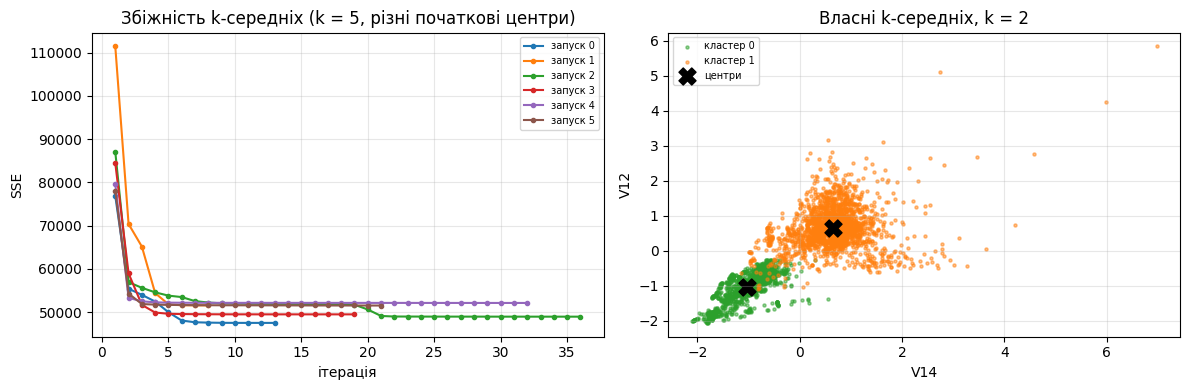

In [8]:
D_t, y_t = draw(3000, seed=0)
Z_t = prep(V)(D_t, None)

rng = np.random.default_rng(RANDOM_STATE)
for k in [2, 5]:
    c0 = Z_t[rng.choice(len(Z_t), k, replace=False)]
    mine = KMeansManual(k).fit(Z_t, init_centers=c0)
    ref = KMeans(k, init=c0, n_init=1, tol=1e-10, max_iter=500).fit(Z_t)
    print(f"k = {k}: ARI між розбиттями = {adjusted_rand_score(mine.labels_, ref.labels_):.4f}; "
          f"SSE власна = {mine.inertia_:.2f}, sklearn = {ref.inertia_:.2f}; ітерацій до збіжності: {len(mine.history_)}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in range(6):                                          # збіжність при різних випадкових початкових центрах
    m = KMeansManual(5, init="random", random_state=s).fit(Z_t)
    ax[0].plot(range(1, len(m.history_) + 1), m.history_, marker="o", ms=3, label=f"запуск {s}")
ax[0].set_xlabel("ітерація"); ax[0].set_ylabel("SSE"); ax[0].set_title("Збіжність k-середніх (k = 5, різні початкові центри)"); ax[0].legend(fontsize=7)

m2 = KMeansManual(2, init="k-means++").fit(Z_t)             # розбиття k = 2 у площині двох найінформативніших ознак
i1, i2 = V.index(INFORMATIVE.index[0]), V.index(INFORMATIVE.index[1])
for c in range(2):
    ax[1].scatter(Z_t[m2.labels_ == c, i1], Z_t[m2.labels_ == c, i2], s=5, alpha=0.5, color=["tab:green", "tab:orange"][c], label=f"кластер {c}")
ax[1].scatter(m2.centers_[:, i1], m2.centers_[:, i2], marker="X", s=150, color="black", label="центри")
ax[1].set_xlabel(INFORMATIVE.index[0]); ax[1].set_ylabel(INFORMATIVE.index[1]); ax[1].set_title("Власні k-середніх, k = 2"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Висновок.** Власна реалізація k-середніх із тими самими початковими центрами дає таке саме розбиття, як `KMeans` (ARI між розбиттями = 1.0000; SSE 61 729.78 при k = 2 та 52 517.12 при k = 5, 11 і 32 ітерації). SSE на кожній ітерації монотонно зменшується, але при k = 5 різні випадкові початкові центри приводять до різних кінцевих значень (приблизно від 47.7 до 52 тис.): алгоритм сходиться до локального мінімуму, який залежить від ініціалізації. Варіант k-медіан реалізований тим самим класом (`center="median"`) і використовується в п. 7.4 та 9.

## 5. Реалізація ієрархічної (агломеративної) кластеризації
Алгоритм «знизу вгору»: спочатку кожен об'єкт — окремий кластер; на кожному кроці зливаємо два найближчі кластери, доки не залишиться один. Послідовність злиттів з їхніми висотами (відстанями) — це дендрограма; розбиття на $k$ кластерів отримуємо, «обрізаючи» дендрограму на відповідному рівні. Відстань між кластерами визначає тип зв'язку (з методички):
- **single** — мінімальна відстань між об'єктами двох кластерів;
- **complete** — максимальна відстань;
- **average** — середня відстань;
- **ward** — злиття, що найменше збільшує внутрішньокластерну дисперсію.

Нижче — власна реалізація на матриці відстаней (після кожного злиття відстані до нового кластера перераховуються за формулою Ланса–Вільямса), складність $O(n^3)$. Результат перевіряємо порівнянням із `scipy.cluster.hierarchy.linkage`.

In [9]:
class AgglomerativeManual:
    """Агломеративна кластеризація; linkage: "single" | "complete" | "average" | "ward"."""

    def __init__(self, linkage="ward"):
        self.linkage = linkage

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n, ward = len(X), self.linkage == "ward"
        D = squareform(pdist(X))
        if ward:
            D = D ** 2                                       # формула Ланса–Вільямса для Уорда працює з квадратами відстаней
        np.fill_diagonal(D, np.inf)
        size, ids, Z = np.ones(n), list(range(n)), []
        for step in range(n - 1):
            i, j = np.unravel_index(np.argmin(D), D.shape)  # найближча пара кластерів
            i, j = min(i, j), max(i, j)
            h, ni, nj = D[i, j], size[i], size[j]
            if self.linkage == "single":
                new = np.minimum(D[i], D[j])
            elif self.linkage == "complete":
                new = np.maximum(D[i], D[j])
            elif self.linkage == "average":
                new = (ni * D[i] + nj * D[j]) / (ni + nj)
            else:
                new = ((ni + size) * D[i] + (nj + size) * D[j] - size * h) / (ni + nj + size)
            Z.append([ids[i], ids[j], np.sqrt(h) if ward else h, ni + nj])   # запис злиття: кластери, висота, розмір
            D[i, :] = D[:, i] = new                         # i тепер — об'єднаний кластер
            D[i, i] = np.inf
            D[j, :] = D[:, j] = np.inf                      # j більше не існує
            size[i], size[j], ids[i] = ni + nj, 0, n + step
        self.n_, self.Z_ = n, np.array(Z)
        return self

    def labels(self, k):
        """Розбиття на k кластерів: виконуємо перші n − k злиттів."""
        members = {i: [i] for i in range(self.n_)}
        for step in range(self.n_ - k):
            a, b = self.Z_[step, :2].astype(int)
            members[self.n_ + step] = members.pop(a) + members.pop(b)
        lab = np.empty(self.n_, dtype=int)
        for c, idxs in enumerate(members.values()):
            lab[idxs] = c
        return lab

Перевіряємо на вибірці з 300 транзакцій: висоти злиттів і розбиття на k = 2…6 кластерів мають збігатися зі `scipy` для всіх типів зв'язку.

In [10]:
D_s, y_s = draw(300, seed=0)
Z_s = prep(V)(D_s, None)

rows = {}
for link in ["single", "complete", "average", "ward"]:
    mine = AgglomerativeManual(link).fit(Z_s)
    ref = linkage(Z_s, link)
    same_heights = np.abs(np.sort(mine.Z_[:, 2]) - np.sort(ref[:, 2])).max()
    same_labels = min(adjusted_rand_score(mine.labels(k), fcluster(ref, k, "maxclust")) for k in range(2, 7))
    rows[link] = {"макс. різниця висот": same_heights, "мін. ARI розбиттів (k = 2…6)": same_labels}
display(pd.DataFrame(rows).T)

# час: власна реалізація (O(n³)) проти scipy
timing = {}
for n in [100, 200, 400, 800]:
    Zn = prep(V)(draw(n, seed=1)[0], None)
    t0 = time.perf_counter(); AgglomerativeManual("ward").fit(Zn); t_mine = time.perf_counter() - t0
    t0 = time.perf_counter(); linkage(Zn, "ward"); t_ref = time.perf_counter() - t0
    timing[n] = {"власна, с": t_mine, "scipy, с": t_ref}
display(pd.DataFrame(timing).T.rename_axis("n").round(4))

,макс. різниця висот,мін. ARI розбиттів (k = 2…6)
single,0.000000e+00,1.0
complete,0.000000e+00,1.0
average,5.329071e-15,1.0
ward,1.421085e-14,1.0


,"власна, с","scipy, с"
n,,
100,0.0028,0.0005
200,0.0061,0.0011
400,0.0322,0.0040
800,0.2346,0.0149


**Висновок.** Власна агломеративна кластеризація для всіх чотирьох типів зв'язку дає ті самі висоти злиттів, що й `scipy` (максимальна різниця ≈ 1.4·10⁻¹⁴), і ті самі розбиття на k = 2…6 кластерів (ARI = 1). Вона повільніша приблизно у 5–19 разів, а розрив зростає з n (n = 800: ≈ 0.2 с проти ≈ 0.01 с), бо складність її наївної реалізації — O(n³); для експериментів нижче використовуємо бібліотечні реалізації.

## 6. Базові моделі
Базові моделі — `KMeans` (k-means++, 10 запусків) та `AgglomerativeClustering` (зв'язок Ward), у обох `k = 2` (два класи в даних), усі 29 ознак (V1–V28 та Amount) після стандартизації. Вибірка — 5 000 випадкових транзакцій.

In [11]:
D0, y0 = draw(5000, seed=0)
Z0 = prep(FEATURES)(D0, None)
base_labels = {
    "k-середніх": KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(Z0),
    "Ward":       AgglomerativeClustering(2, linkage="ward").fit_predict(Z0),
}
base = pd.DataFrame({name: cluster_scores(Z0, lab, y0) for name, lab in base_labels.items()}).T
display(base[["ARI", "NMI", "accuracy", "silhouette", "precision", "recall"]].round(4))
for name, lab in base_labels.items():
    print(f"\n{name}: кластери проти справжніх класів")
    display(pd.crosstab(lab, y0, rownames=["кластер"], colnames=["клас Class"]))

,ARI,NMI,accuracy,silhouette,precision,recall
k-середніх,0.5600,0.5578,0.8742,0.2845,0.9995,0.7488
Ward,0.1051,0.2257,0.6622,0.3651,1.0000,0.3244



k-середніх: кластери проти справжніх класів


клас Class,0,1
кластер,,
0,1,1872
1,2499,628



Ward: кластери проти справжніх класів


клас Class,0,1
кластер,,
0,2500,1689
1,0,811


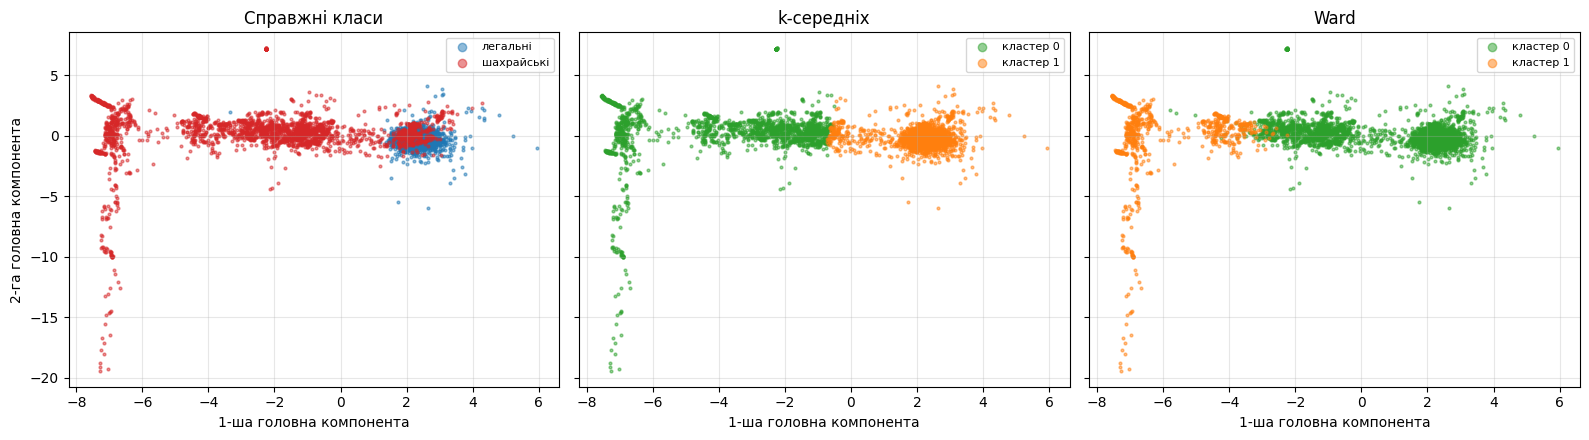

Частка дисперсії, яку пояснюють дві головні компоненти: 0.443


In [12]:
pca = PCA(2, random_state=RANDOM_STATE).fit(Z0)
P0 = pca.transform(Z0)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
panels = [("Справжні класи", y0, ["легальні", "шахрайські"]),
          ("k-середніх", base_labels["k-середніх"], ["кластер 0", "кластер 1"]),
          ("Ward", base_labels["Ward"], ["кластер 0", "кластер 1"])]
for a, (title, lab, names) in zip(ax, panels):
    colors = ["tab:blue", "tab:red"] if title == "Справжні класи" else ["tab:green", "tab:orange"]   # кластери — інші кольори, ніж класи
    for c, color in enumerate(colors):
        a.scatter(P0[lab == c, 0], P0[lab == c, 1], s=4, alpha=0.5, color=color, label=names[c])
    a.set_title(title); a.set_xlabel("1-ша головна компонента"); a.legend(markerscale=3, fontsize=8)
ax[0].set_ylabel("2-га головна компонента")
plt.tight_layout(); plt.show()
print("Частка дисперсії, яку пояснюють дві головні компоненти:", pca.explained_variance_ratio_.sum().round(3))

Одна вибірка може бути нетиповою, тому перевіряємо стабільність: ті самі базові моделі на 8 різних вибірках по 3 000 транзакцій. Для кожної — ARI та частка меншого кластера.

In [13]:
stab = {}
for r in range(8):
    D, yy = draw(3000, seed=r)
    Z = prep(FEATURES)(D, None)
    row = {}
    for name, fit in ALGOS.items():
        lab = fit(Z, 2, r)
        row[(name, "ARI")] = adjusted_rand_score(yy, lab)
        row[(name, "частка меншого кластера")] = np.bincount(lab).min() / len(lab)
    stab[f"вибірка {r}"] = row
stab = pd.DataFrame(stab).T
stab.columns = pd.MultiIndex.from_tuples(stab.columns)
display(stab.round(3))
print("Середній ARI:", stab.xs("ARI", axis=1, level=1).mean().round(3).to_dict(), "| розкид:", stab.xs("ARI", axis=1, level=1).std().round(3).to_dict())

k-середніх                           Ward                        
                 ARI частка меншого кластера    ARI частка меншого кластера
вибірка 0      0.597                   0.386  0.714                   0.429
вибірка 1      0.591                   0.384  0.796                   0.455
вибірка 2      0.616                   0.393  0.665                   0.410
вибірка 3      0.587                   0.384  0.650                   0.408
вибірка 4      0.571                   0.378  0.080                   0.141
вибірка 5      0.554                   0.372  0.537                   0.370
вибірка 6      0.590                   0.384  0.592                   0.397
вибірка 7      0.563                   0.376  0.539                   0.369

Середній ARI: {'k-середніх': 0.584, 'Ward': 0.571} | розкид: {'k-середніх': 0.02, 'Ward': 0.217}


**Висновок.** **k-середніх:** ARI 0.560, accuracy 0.874, силует 0.285. Один кластер майже чисто шахрайський (1 872 шахрайських проти 1 легальної), другий містить 2 499 легальних і 628 шахрайських: precision шахрайського кластера 0.9995, recall 0.749, тобто чверть шахрайських транзакцій схожа на легальні. На PCA-графіку легальні транзакції утворюють компактну групу, а шахрайські — розтягнуту хмару з довгим «хвостом», частина якої накладається на легальні. **Ward** на цій вибірці дав ARI лише 0.105 (accuracy 0.662): першим поділом він відокремив групу з 811 суто шахрайських транзакцій («хвіст» ліворуч), а решта (2 500 легальних і 1 689 шахрайських) лишилась разом. Силует у Ward вищий (0.365 проти 0.285), хоча відповідність класам гірша, тож силует тут класи не відображає. Перевірка на 8 вибірках показує, що це не випадковість: ARI k-середніх майже не змінюється (0.554–0.616, розкид 0.020), а Ward коливається від 0.080 до 0.796 (розкид 0.217). Де менший кластер лише 14% вибірки, ARI = 0.08, а де 37–46%, ARI = 0.54–0.80.

## 7. Залежність точності від параметрів даних
Змінюємо по одній особливості даних (або налаштуванню алгоритму), решта — як у базовій моделі: усі 29 ознак стандартизовані, `k = 2`, вибірки по 3 000 транзакцій, 8 повторів. Основна метрика — ARI відносно `Class`; додатково — accuracy (чистота) та силует. Підсумкові значення ARI збираємо в `FACTORS`, щоб у кінці порівняти чутливість до кожного фактора.

In [14]:
FACTORS = {}

def bar_ari(df, title, figsize=(9, 4.5)):
    ax = df.plot.barh(figsize=figsize, width=0.8, color=["tab:blue", "tab:red", "tab:green"][:df.shape[1]])
    ax.invert_yaxis(); ax.set_xlabel("ARI відносно міток Class (середнє по вибірках)"); ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

### 7.1. Масштабування ознак
Обидва алгоритми працюють із відстанями, тому масштаб ознак визначає, які з них «вирішують» долю об'єкта. `Amount` має діапазон до 24 000, а `V1`–`V28` — порядку одиниць. Порівнюємо відсутність масштабування, стандартизацію, нормалізацію до [0, 1] та робастне масштабування (медіана й міжквартильний розмах).

In [15]:
SCALERS = {"без масштабування": None, "StandardScaler": StandardScaler, "MinMaxScaler": MinMaxScaler, "RobustScaler": RobustScaler}
res_scale = {name: evaluate(prep(FEATURES, scaler=s)) for name, s in SCALERS.items()}
FACTORS["Масштабування"] = metric_of(res_scale)
display(table(res_scale).round(4))

# дисперсія ознак після масштабування — пояснює результати
D_v, _ = draw(N_EXP, seed=0)
var_after = {name: pd.DataFrame(s().fit_transform(D_v[FEATURES]) if s else D_v[FEATURES].to_numpy(), columns=FEATURES).var()
             for name, s in SCALERS.items()}
display(pd.DataFrame({name: {"V1–V28: медіана": v[V].median(), "V1–V28: максимум": v[V].max(), "Amount": v["Amount"]}
                      for name, v in var_after.items()}).T.map("{:.3g}".format))

k-середніх                                Ward          \
                         ARI   ± ARI accuracy silhouette     ARI   ± ARI   
без масштабування     0.0002  0.0004   0.5104     0.6297 -0.0000  0.0002   
StandardScaler        0.5836  0.0197   0.8820     0.2766  0.5714  0.2171   
MinMaxScaler          0.5878  0.0140   0.8834     0.2629  0.6889  0.0347   
RobustScaler          0.0094  0.0128   0.5343     0.7064  0.0050  0.0137   

                                       
                  accuracy silhouette  
без масштабування   0.5075     0.5894  
StandardScaler      0.8673     0.2658  
MinMaxScaler        0.9149     0.2483  
RobustScaler        0.5188     0.7787

,V1–V28: медіана,V1–V28: максимум,Amount
без масштабування,0.972,1.17,4.81e+07
StandardScaler,1,1,1
MinMaxScaler,0.0109,0.0425,0.0837
RobustScaler,0.792,17.8,0.339


**Висновок.** Масштабування вирішальне. Без нього ARI ≈ 0 для обох методів (0.0002 та −0.0000): дисперсія `Amount` (4.8·10⁷) приблизно в 5·10⁷ разів більша за дисперсію `V`, тож відстані визначає лише `Amount`, а він з класом не пов'язаний. При цьому силует для цього розбиття високий (0.63 / 0.59 проти 0.28 / 0.27 у StandardScaler). StandardScaler дає 0.584 ± 0.020 (k-середніх) і 0.571 ± 0.217 (Ward). MinMaxScaler — 0.588 ± 0.014 та 0.689 ± 0.035: для k-середніх різниця в межах розкиду, а Ward став помітно стабільнішим (розкид 0.035 проти 0.217), імовірно тому, що після MinMax дисперсія важкохвостих ознак стиснута (медіана дисперсій `V` — 0.011, максимум 0.043, у `Amount` — 0.084). RobustScaler зруйнував результат (ARI 0.009 / 0.005, силует 0.71 / 0.78): медіана й міжквартильний розмах викиди не обмежують, тому дисперсія важкохвостої ознаки після масштабування сягає 17.8 (медіана по `V` — 0.79) і вона домінує у відстанях.

### 7.2. Набір ознак
Кластеризуємо різні підмножини ознак, щоб побачити, які з них несуть кластерну структуру, а які лише «розмивають» відстані. Відбір «найінформативніших» ознак зроблено за міткою (п. 2), тому це верхня межа, а не чесний метод. Окремо перевіряємо колонку `id`: як показав п. 2, рядки у файлі впорядковані за класом.

k-середніх                   \
                                                  ARI   ± ARI accuracy   
лише Amount                                    0.0002  0.0004   0.5103   
V1–V7                                          0.1656  0.0208   0.7032   
V1–V14                                         0.6030  0.0342   0.8882   
V1–V28                                         0.5832  0.0195   0.8818   
V1–V28 + Amount (базова)                       0.5836  0.0197   0.8820   
10 найінформативніших V (відбір за міткою)     0.6138  0.0157   0.8918   
5 найінформативніших V (відбір за міткою)      0.6911  0.0192   0.9157   
10 найменш інформативних V (за міткою)         0.0023  0.0033   0.5202   
лише id (артефакт датасету)                    0.9831  0.0148   0.9958   
V1–V28 + id                                    0.6241  0.0152   0.8950   

                                                         Ward          \
                                           silhouette     ARI   ± ARI   
лише Amount                                    0.6297  0.0001  0.0005   
V1–V7                                          0.4521  0.1116  0.1710   
V1–V14                                         0.3840  0.6785  0.0532   
V1–V28                                         0.2883  0.2900  0.2763   
V1–V28 + Amount (базова)                       0.2766  0.5714  0.2171   
10 найінформативніших V (відбір за міткою)     0.4858  0.6657  0.0241   
5 найінформативніших V (відбір за міткою)      0.5525  0.8025  0.0187   
10 найменш інформативних V (за міткою)         0.0988  0.0004  0.0004   
лише id (артефакт датасету)                    0.6230  0.7326  0.1758   
V1–V28 + id                                    0.2911  0.7191  0.0407   

                                                                
                                           accuracy silhouette  
лише Amount                                  0.5080     0.5910  
V1–V7                                        0.6447     0.5045  
V1–V14                                       0.9116     0.3738  
V1–V28                                       0.7423     0.3299  
V1–V28 + Amount (базова)                     0.8673     0.2658  
10 найінформативніших V (відбір за міткою)   0.9079     0.4769  
5 найінформативніших V (відбір за міткою)    0.9479     0.5254  
10 найменш інформативних V (за міткою)       0.5093     0.6206  
лише id (артефакт датасету)                  0.9251     0.6045  
V1–V28 + id                                  0.9239     0.2652

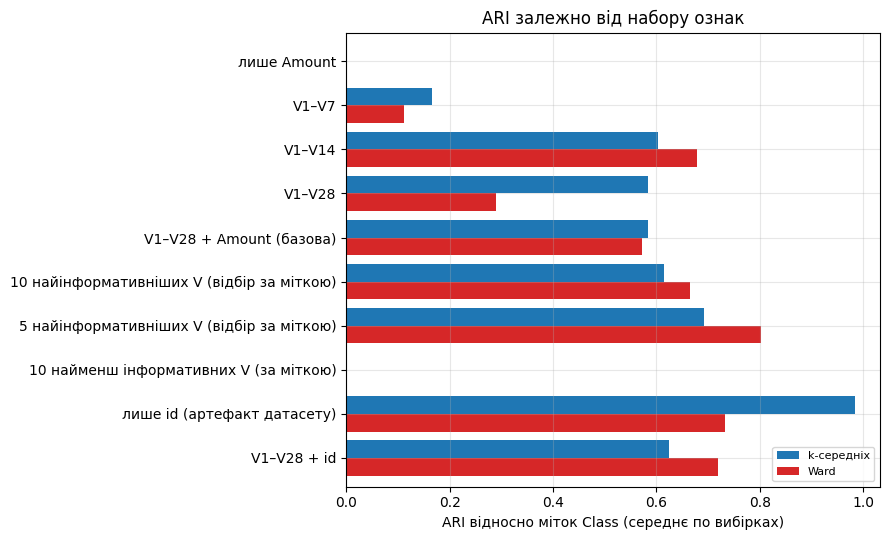

In [16]:
INF = list(INFORMATIVE.index.drop("Amount"))      # V-ознаки від найінформативніших до найменш інформативних
subsets = {
    "лише Amount":                                  ["Amount"],
    "V1–V7":                                        V[:7],
    "V1–V14":                                       V[:14],
    "V1–V28":                                       V,
    "V1–V28 + Amount (базова)":                     FEATURES,
    "10 найінформативніших V (відбір за міткою)":   INF[:10],
    "5 найінформативніших V (відбір за міткою)":    INF[:5],
    "10 найменш інформативних V (за міткою)":       INF[-10:],
    "лише id (артефакт датасету)":                  ["id"],
    "V1–V28 + id":                                  V + ["id"],
}
res_sub = {name: evaluate(prep(cols)) for name, cols in subsets.items()}
FACTORS["Набір ознак"] = metric_of(res_sub)
display(table(res_sub).round(4))
bar_ari(FACTORS["Набір ознак"], "ARI залежно від набору ознак", figsize=(9, 5.5))

**Висновок.** Кластерна структура зосереджена в частині ознак `V`. `Amount` окремо дає ARI ≈ 0, 10 найменш інформативних `V` — теж ≈ 0 (0.002 / 0.0004), `V1`–`V7` — слабко (0.166 / 0.112), а вже `V1`–`V14` дають 0.603 (k-середніх) і 0.679 (Ward). Додавання решти ознак не покращує: `V1`–`V28` — 0.583 і 0.290 ± 0.276 (Ward стає нестабільним), додавання `Amount` нічого не змінює для k-середніх (0.584). Найкращий результат дають 5 найінформативніших ознак: 0.691 і 0.803 ± 0.019 (але їх відібрано за міткою, тому це верхня межа, а не чесний метод). Колонка `id` — артефакт датасету: k-середніх лише за нею дають ARI 0.983, бо класи у файлі впорядковані, а не тому, що знайдено шахрайство; навіть одна така колонка серед 29 піднімає ARI з 0.583 до 0.624 і створює хибне враження кращої якості. Силует між різними наборами ознак порівнювати не можна: він високий для `Amount` окремо (0.63 при ARI ≈ 0), а для всіх 28 `V` — лише 0.29 при значно кращому ARI.

### 7.3. Шумові (нерелевантні) ознаки
До 5 найінформативніших ознак додаємо `N` ознак із випадковим шумом `N(0, 1)`, не пов'язаних із міткою: так імітується датасет із багатьма неінформативними колонками. Дивимось і на ARI, і на силует (внутрішню метрику).

k-середніх                       Ward          \
                               ARI   ± ARI silhouette     ARI   ± ARI   
кількість шумових ознак                                                 
0                           0.6911  0.0192     0.5525  0.8025  0.0187   
5                           0.6910  0.0189     0.2858  0.7438  0.0241   
10                          0.6913  0.0200     0.1963  0.7240  0.0319   
25                          0.6913  0.0191     0.1020  0.6400  0.0356   
50                          0.6922  0.0231     0.0570  0.5353  0.0412   
100                         0.6923  0.0204     0.0303  0.4277  0.0203   

                                    
                        silhouette  
кількість шумових ознак             
0                           0.5254  
5                           0.2766  
10                          0.1887  
25                          0.0942  
50                          0.0494  
100                         0.0227

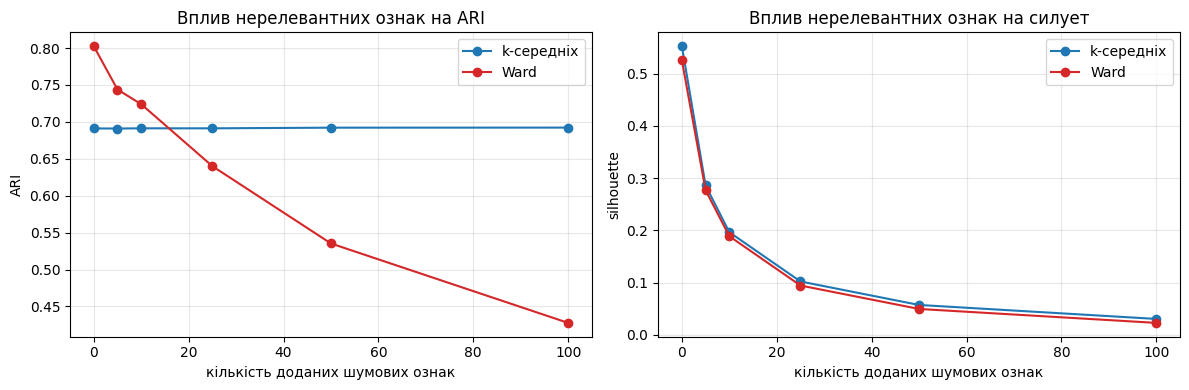

In [17]:
NOISE = [0, 5, 10, 25, 50, 100]
res_noise = {n: evaluate(prep(INF[:5], noise=n)) for n in NOISE}
FACTORS["Шумові ознаки"] = metric_of(res_noise)
display(table(res_noise, metrics=("ARI", "silhouette")).rename_axis("кількість шумових ознак").round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
metric_of(res_noise, "ARI").plot(marker="o", ax=ax[0], color=["tab:blue", "tab:red"]); ax[0].set_ylabel("ARI")
metric_of(res_noise, "silhouette").plot(marker="o", ax=ax[1], color=["tab:blue", "tab:red"]); ax[1].set_ylabel("silhouette")
for a in ax:
    a.set_xlabel("кількість доданих шумових ознак"); a.legend()
ax[0].set_title("Вплив нерелевантних ознак на ARI"); ax[1].set_title("Вплив нерелевантних ознак на силует")
plt.tight_layout(); plt.show()

**Висновок.** k-середніх до шумових ознак практично нечутливі: ARI залишається 0.691–0.692 (розкид ≈ 0.02) від 0 до 100 доданих шумових ознак. Можливе пояснення: центри кластерів усереднюють випадковий шум, тож розбиття при k = 2 визначається різницею центрів в інформативних ознаках. Ward будує розбиття з відстаней між парами об'єктів, у яких шум накопичується, тому його ARI монотонно падає з 0.803 до 0.428. Силует падає в обох методів (k-середніх: 0.553 → 0.030, Ward: 0.525 → 0.023), тобто він реагує на шум навіть там, де відповідність класам не змінюється (k-середніх).

### 7.4. Викиди та варіант алгоритму
Багато ознак `V` мають дуже важкі «хвости» (п. 2): окремі значення відхиляються на десятки стандартних відхилень. Перевіряємо, чи допомагає обмеження викидів (після стандартизації значення обрізаються до `|z| ≤ c`) та чи стійкіший варіант k-медіан (власна реалізація з розділу 4, манхеттенська відстань, центр — медіана).

In [18]:
OUT_ALGOS = {**ALGOS, "k-медіан": lambda Z, k, seed: KMeansManual(k, init="k-means++", center="median", n_init=10, random_state=seed).fit(Z).labels_}
CLIPS = {"без обробки": None, "обмеження |z| ≤ 5": 5, "обмеження |z| ≤ 3": 3, "обмеження |z| ≤ 2": 2}
res_out = {name: evaluate(prep(FEATURES, clip=c), algos=OUT_ALGOS) for name, c in CLIPS.items()}
FACTORS["Викиди"] = metric_of(res_out)
display(table(res_out, metrics=("ARI", "accuracy")).round(4))

k-середніх                     Ward                   \
                         ARI   ± ARI accuracy     ARI   ± ARI accuracy   
без обробки           0.5836  0.0197   0.8820  0.5714  0.2171   0.8673   
обмеження |z| ≤ 5     0.5799  0.0248   0.8807  0.5301  0.2685   0.8480   
обмеження |z| ≤ 3     0.5857  0.0183   0.8827  0.5332  0.2729   0.8486   
обмеження |z| ≤ 2     0.6019  0.0182   0.8879  0.7391  0.0785   0.9293   

                  k-медіан                   
                       ARI   ± ARI accuracy  
без обробки         0.6212  0.0198   0.8941  
обмеження |z| ≤ 5   0.6212  0.0198   0.8941  
обмеження |z| ≤ 3   0.6212  0.0198   0.8941  
обмеження |z| ≤ 2   0.6212  0.0198   0.8941

**Висновок.** Для k-середніх обмеження викидів майже нічого не змінює: 0.584 → 0.580 / 0.586 / 0.602 при |z| ≤ 5 / 3 / 2, різниці в межах розкиду (≈ 0.02). Для Ward користь є лише при жорсткому порозі |z| ≤ 2: ARI 0.739 ± 0.079 проти 0.571 ± 0.217 без обробки (м'якші пороги дають 0.530 і 0.533), тобто середнє зростає, а розкид зменшується майже втричі. K-медіан дають 0.621 ± 0.020, що вище за k-середніх (різниця ≈ 2 розкиди), а результат однаковий для всіх порогів: медіана та манхеттенська відстань не залежать від того, наскільки далеко лежить викид, тому обмеження нічого не змінює.

### 7.5. Дисбаланс класів
У датасеті шахрайських і легальних транзакцій порівну, але в реальних системах шахрайство трапляється значно рідше. Зменшуємо частку шахрайських транзакцій у вибірці з 5 000 об'єктів (ознаки V1–V28). Для кластера з найбільшою часткою шахрайських транзакцій рахуємо precision і recall.

k-середніх                                       Ward  \
                          ARI   ± ARI accuracy precision  recall     ARI   
частка шахрайських                                                         
50.0%                  0.5691  0.0293   0.8771    0.9997  0.7544  0.4224   
30.0%                  0.7311  0.0097   0.9312    0.9992  0.7711  0.7275   
10.0%                  0.8465  0.0124   0.9786    0.9968  0.7882  0.8107   
5.0%                   0.8342  0.0286   0.9872    0.9955  0.7465  0.8563   
1.0%                  -0.0004  0.0006   0.9900    0.0137  0.8850  0.0064   
0.2%                  -0.0001  0.0001   0.9980    0.0031  0.7875 -0.0013   

                                                      
                     ± ARI accuracy precision recall  
частка шахрайських                                    
50.0%               0.3300   0.7982    0.9936  0.602  
30.0%               0.1833   0.9284    0.9865  0.773  
10.0%               0.1457   0.9748    0.9905  0.754  
5.0%                0.0257   0.9887    0.9939  0.779  
1.0%                0.0198   0.9900    0.0244  0.880  
0.2%                0.0012   0.9980    0.0020  1.000

Тривіальна accuracy (усе вважати легальним): {'50.0%': 0.5, '30.0%': 0.7, '10.0%': 0.9, '5.0%': 0.95, '1.0%': 0.99, '0.2%': 0.998}


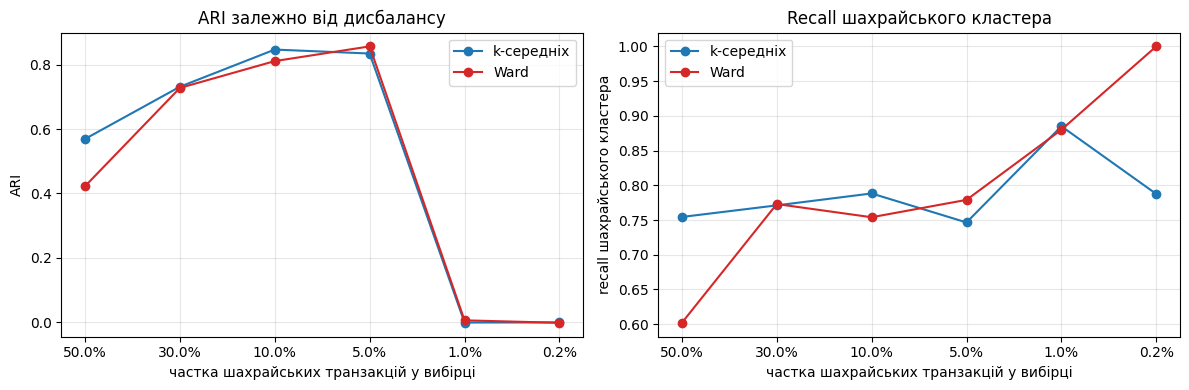

In [19]:
FRACS = [0.5, 0.3, 0.1, 0.05, 0.01, 0.002]
res_bal = {f"{f:.1%}": evaluate(prep(V), n=5000, frac=f) for f in FRACS}
FACTORS["Дисбаланс класів"] = metric_of(res_bal)
display(table(res_bal, metrics=("ARI", "accuracy", "precision", "recall")).rename_axis("частка шахрайських").round(4))
print("Тривіальна accuracy (усе вважати легальним):", {k: round(1 - float(k.strip("%")) / 100, 4) for k in res_bal})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
metric_of(res_bal, "ARI").plot(marker="o", ax=ax[0], color=["tab:blue", "tab:red"]); ax[0].set_ylabel("ARI")
metric_of(res_bal, "recall").plot(marker="o", ax=ax[1], color=["tab:blue", "tab:red"]); ax[1].set_ylabel("recall шахрайського кластера")
for a in ax:
    a.set_xlabel("частка шахрайських транзакцій у вибірці"); a.legend()
ax[0].set_title("ARI залежно від дисбалансу"); ax[1].set_title("Recall шахрайського кластера")
plt.tight_layout(); plt.show()

**Висновок.** Чим рідше шахрайство, тим вищий ARI, поки клас ще утворює окремий кластер: у k-середніх 0.569 при 50% → 0.847 при 10% і 0.834 при 5%, хоча recall шахрайського кластера майже не змінюється (0.75–0.79), а precision ≈ 0.996–1.000. ARI росте тому, що ті самі ≈ 21–25% «пропущених» шахрайських транзакцій становлять дедалі меншу частку даних. Починаючи з 1% (50 шахрайських у вибірці з 5 000) ARI ≈ 0 для обох методів (k-середніх −0.0004, Ward 0.006), а precision «шахрайського» кластера падає до 0.014 / 0.024: алгоритми більше не виділяють шахрайство в окремий кластер. Accuracy (0.990 та 0.998) збігається з тривіальною (усе вважати легальним) і нічого не показує. У реальних даних шахрайство рідкісне, тож результати на збалансованому датасеті для практики оптимістичні.

### 7.6. Кількість кластерів k
Ключовий параметр обох алгоритмів. Дивимось, як змінюються SSE (метод «ліктя»), силует та ARI, і чи можна визначити правильне `k = 2` без міток — за внутрішніми метриками.

k-середніх                                Ward                            
          ARI   ± ARI accuracy silhouette     ARI   ± ARI accuracy silhouette
k                                                                            
2      0.5832  0.0195   0.8818     0.2883  0.2900  0.2763   0.7423     0.3299
3      0.5297  0.0277   0.9032     0.2383  0.5513  0.0622   0.9194     0.2023
4      0.5155  0.0120   0.9064     0.2329  0.5425  0.0614   0.9194     0.2061
5      0.4953  0.0463   0.9104     0.2219  0.5360  0.0614   0.9194     0.2136
6      0.4616  0.0652   0.9109     0.2021  0.5022  0.0227   0.9275     0.2114
8      0.3267  0.0132   0.9361     0.1457  0.4971  0.0175   0.9316     0.2125
10     0.3130  0.0750   0.9364     0.1468  0.4812  0.0153   0.9316     0.1985

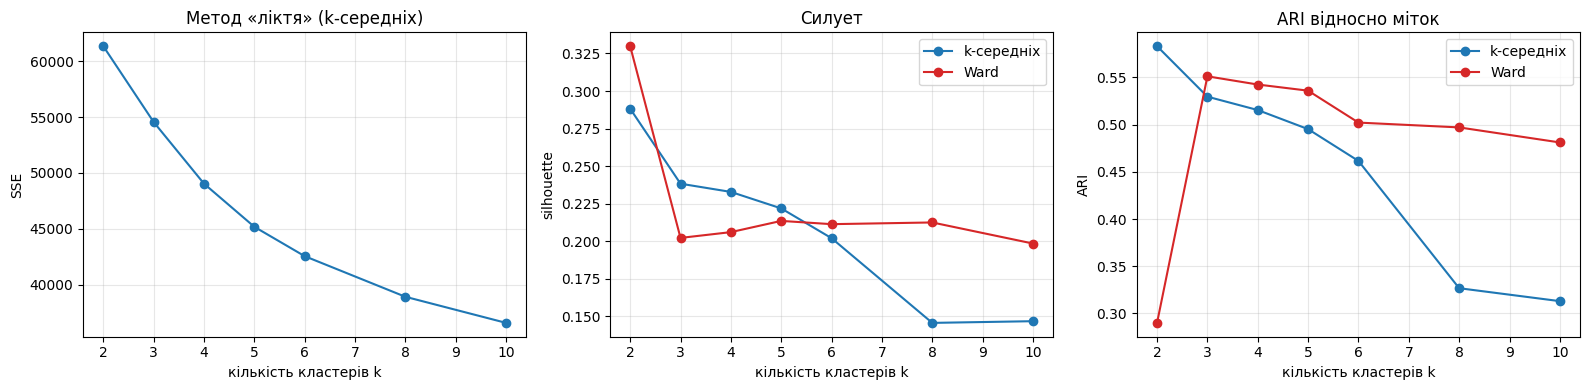

In [20]:
KS = [2, 3, 4, 5, 6, 8, 10]
res_k = {k: evaluate(prep(V), k=k) for k in KS}
FACTORS["Кількість кластерів k"] = metric_of(res_k)
display(table(res_k).rename_axis("k").round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
metric_of(res_k, "SSE")["k-середніх"].plot(marker="o", ax=ax[0], color="tab:blue"); ax[0].set_ylabel("SSE"); ax[0].set_title("Метод «ліктя» (k-середніх)")
metric_of(res_k, "silhouette").plot(marker="o", ax=ax[1], color=["tab:blue", "tab:red"]); ax[1].set_ylabel("silhouette"); ax[1].set_title("Силует")
metric_of(res_k, "ARI").plot(marker="o", ax=ax[2], color=["tab:blue", "tab:red"]); ax[2].set_ylabel("ARI"); ax[2].set_title("ARI відносно міток")
for a in ax:
    a.set_xlabel("кількість кластерів k")
plt.tight_layout(); plt.show()

**Висновок.** ARI k-середніх найвищий при k = 2 (0.583) і зменшується до 0.313 при k = 10, а accuracy (чистота) зростає з 0.882 до 0.936, бо дроблення кластерів завжди підвищує чистоту. Силует також максимальний при k = 2 (0.288 у k-середніх, 0.330 у Ward), тож правильну кількість класів можна визначити без міток. Метод «ліктя» тут не допомагає: SSE зменшується плавно (≈ 61 тис. при k = 2 → ≈ 37 тис. при k = 10) без явного згину. У Ward при k = 2 ARI нестабільний (0.290 ± 0.276), а при k = 3 — 0.551 ± 0.062 і далі повільно знижується до 0.481 при k = 10.

### 7.7. Ініціалізація центрів (k-середніх)
Методика називає залежність від початкових центрів головним недоліком k-середніх. Запускаємо алгоритм 30 разів із різними `random_state` на одній вибірці з 20 000 транзакцій: випадкові початкові центри чи k-means++, один запуск (`n_init = 1`) чи кращий із 10.

SSE середнє     SSE мін    SSE макс  \
k ініціалізація n_init                                        
2 random        1        413430.319  408671.700  551422.645   
                10       408671.731  408671.700  408671.794   
  k-means++     1        417443.244  408671.726  551422.787   
                10       408671.730  408671.707  408671.794   
5 random        1        329753.487  311825.876  353119.090   
                10       311474.325  299093.219  318790.407   
  k-means++     1        316172.907  299093.842  341923.282   
                10       302137.121  299093.219  314007.712   

                        різних значень SSE  ARI середнє  ARI мін  ARI макс  
k ініціалізація n_init                                                      
2 random        1                      2.0        0.566    0.000     0.587  
                10                     1.0        0.583    0.583     0.584  
  k-means++     1                      3.0        0.546    0.000     0.587  
                10                     1.0        0.583    0.583     0.584  
5 random        1                     22.0        0.478    0.359     0.547  
                10                     5.0        0.537    0.503     0.544  
  k-means++     1                     16.0        0.494    0.381     0.544  
                10                     4.0        0.510    0.491     0.539

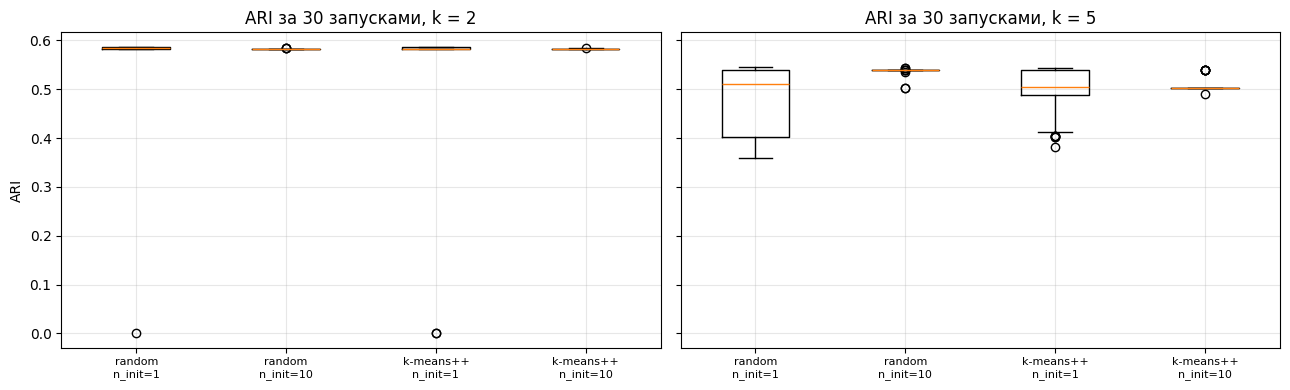

In [21]:
D_i, y_i = draw(20000, seed=0)
Z_i = prep(V)(D_i, None)

rows, runs = {}, {}
for k in [2, 5]:
    for init in ["random", "k-means++"]:
        for n_init in [1, 10]:
            fits = [KMeans(k, init=init, n_init=n_init, random_state=s).fit(Z_i) for s in range(30)]
            sse = np.array([m.inertia_ for m in fits])
            a = np.array([adjusted_rand_score(y_i, m.labels_) for m in fits])
            rows[(k, init, n_init)] = {"SSE середнє": sse.mean(), "SSE мін": sse.min(), "SSE макс": sse.max(),
                                       "різних значень SSE": len(np.unique(sse.round(0))),
                                       "ARI середнє": a.mean(), "ARI мін": a.min(), "ARI макс": a.max()}
            runs[(k, init, n_init)] = a
res_init = pd.DataFrame(rows).T.rename_axis(["k", "ініціалізація", "n_init"])
display(res_init.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a_, k in zip(ax, [2, 5]):
    keys = [key for key in runs if key[0] == k]
    a_.boxplot([runs[key] for key in keys])
    a_.set_xticklabels([f"{key[1]}\nn_init={key[2]}" for key in keys])
    a_.set_title(f"ARI за 30 запусками, k = {k}"); a_.tick_params(axis="x", labelsize=8)
ax[0].set_ylabel("ARI")
plt.tight_layout(); plt.show()
FACTORS["Випадкова ініціалізація (n_init = 1)"] = pd.DataFrame({"k-середніх": runs[(2, "random", 1)]})

**Висновок.** Ініціалізація — головне джерело нестабільності k-середніх. При k = 2 і одному запуску частина із 30 запусків (один при випадкових центрах і два при k-means++) потрапила у слабкий локальний мінімум (SSE 551 423 проти 408 672 в оптимумі, ARI 0.000 проти 0.587). З `n_init = 10` усі 30 запусків дають практично однаковий SSE і ARI 0.583–0.584. При k = 5 локальних мінімумів більше (22 різні значення SSE у 30 запусках для випадкової ініціалізації, 16 для k-means++; ARI 0.36–0.55). k-means++ дає нижчий SSE (у середньому 316 173 проти 329 753 при `n_init = 1`), але менший SSE не гарантує кращого збігу з класами: при `n_init = 10` середній ARI з випадковою ініціалізацією (0.537) вищий, ніж із k-means++ (0.510).

### 7.8. Тип зв'язку та метрика відстані (ієрархічна кластеризація)
Для ієрархічної кластеризації додатково важливі тип зв'язку та метрика відстані (методика: максимум, мінімум, середнє). Спочатку порівнюємо типи зв'язку для різних `k` (евклідова відстань), потім — метрики для `k = 2`, потім — вплив обмеження викидів. Для кожного розбиття дивимось ще й на частку найбільшого кластера: значення, близьке до 1, означає, що алгоритм лише «відколює» окремі об'єкти. Через обсяг обчислень тут 5 повторів.

In [22]:
LINKS, KS_H, REP_H = ["ward", "complete", "average", "single"], [2, 3, 5, 10, 20], 5

def agg(link, metric="euclidean"):
    return lambda Z, k, seed: AgglomerativeClustering(k, linkage=link, metric=metric).fit_predict(Z)

res_link = {link: {k: evaluate(prep(V), k=k, algos={link: agg(link)}, repeats=REP_H)[link] for k in KS_H} for link in LINKS}
ari_link = pd.DataFrame({link: {k: st.loc["mean", "ARI"] for k, st in d.items()} for link, d in res_link.items()}).rename_axis("k")
share_link = pd.DataFrame({link: {k: st.loc["mean", "max_share"] for k, st in d.items()} for link, d in res_link.items()}).rename_axis("k")
print("ARI (евклідова відстань, V1–V28):");                display(ari_link.round(3))
print("Частка найбільшого кластера:");                      display(share_link.round(3))
FACTORS["Тип зв'язку (k = 2)"] = pd.DataFrame({"ієрархічна": ari_link.loc[2]})

ARI (евклідова відстань, V1–V28):


,ward,complete,average,single
k,,,,
2,0.318,0.000,0.000,0.0
3,0.558,0.000,0.000,0.0
5,0.543,0.127,0.000,0.0
10,0.473,0.144,0.001,0.0
20,0.198,0.334,0.031,0.0


Частка найбільшого кластера:


,ward,complete,average,single
k,,,,
2,0.746,0.996,0.999,1.000
3,0.569,0.992,0.999,0.999
5,0.569,0.906,0.996,0.994
10,0.559,0.823,0.976,0.989
20,0.255,0.580,0.896,0.985


In [23]:
METRICS = ["euclidean", "manhattan", "cosine", "chebyshev"]
res_met = {(link, m): evaluate(prep(V), algos={"x": agg(link, m)}, repeats=REP_H)["x"] for link in ["average", "complete", "single"] for m in METRICS}
ari_met = pd.DataFrame({m: {link: res_met[(link, m)].loc["mean", "ARI"] for link in ["average", "complete", "single"]} for m in METRICS})
share_met = pd.DataFrame({m: {link: res_met[(link, m)].loc["mean", "max_share"] for link in ["average", "complete", "single"]} for m in METRICS})
print("ARI, k = 2 (Ward визначений лише для евклідової відстані):"); display(ari_met.round(3))
print("Частка найбільшого кластера:");                                display(share_met.round(3))
FACTORS["Метрика відстані (average, k = 2)"] = pd.DataFrame({"ієрархічна": ari_met.loc["average"]})

# вплив обмеження викидів на зв'язки complete та average (k = 2)
res_clip = {(link, name): evaluate(prep(V, clip=c), algos={"x": agg(link)}, repeats=REP_H)["x"]
            for link in ["complete", "average"] for name, c in [("без обробки", None), ("|z| ≤ 3", 3)]}
display(pd.DataFrame({f"{link}, {name}": {"ARI": st.loc["mean", "ARI"], "частка найбільшого кластера": st.loc["mean", "max_share"]}
                      for (link, name), st in res_clip.items()}).T.round(3))

ARI, k = 2 (Ward визначений лише для евклідової відстані):


,euclidean,manhattan,cosine,chebyshev
average,0.0,0.0,0.636,0.0
complete,0.0,0.0,0.628,0.0
single,0.0,0.0,0.000,0.0


Частка найбільшого кластера:


,euclidean,manhattan,cosine,chebyshev
average,0.999,0.999,0.592,1.000
complete,0.996,0.991,0.600,0.999
single,1.000,1.000,1.000,1.000


,ARI,частка найбільшого кластера
"complete, без обробки",0.000,0.996
"complete, |z| ≤ 3",0.351,0.765
"average, без обробки",0.000,0.999
"average, |z| ≤ 3",0.001,0.986


**Висновок.** На V1–V28 осмислений результат у відстані Евкліда дає лише Ward (ARI 0.318 при k = 2, 0.558 при k = 3). Зв'язки complete, average і single при k = 2 дають ARI = 0.000, а частка найбільшого кластера 0.996–1.000: алгоритм відколює поодинокі викиди, а основна маса лишається разом. Complete починає працювати лише при k ≥ 5 (0.127 → 0.334 при k = 20), average — майже ніколи (0.031 при k = 20), single — ніколи (0.000). Метрика важлива не менше: евклідова, манхеттенська та Чебишова дають 0.000 для average і complete, а косинусна — 0.636 і 0.628 зі збалансованими кластерами (найбільший 0.59–0.60). Імовірно, косинусна відстань враховує лише напрямок вектора, а не його довжину, тому віддалені викиди не відокремлюються. Для single навіть вона дає 0. Обмеження викидів |z| ≤ 3 піднімає complete з 0.000 до 0.351, а average (0.001) лишається чутливим. Отже, при важких «хвостах» зв'язки max/min/average з евклідовою відстанню ненадійні.

### 7.9. Дендрограма та поріг відстані
Перевага ієрархічної кластеризації — дендрограма, яка дозволяє не задавати `k` заздалегідь: кількість кластерів визначається порогом відстані. Ліворуч — дендрограма Ward для 80 транзакцій (підписи листків: 0 — легальна, 1 — шахрайська; пунктир — поріг, що дає два кластери), праворуч — висоти останніх злиттів для вибірки з 3 000 транзакцій. Далі — таблиця «поріг → кількість кластерів → ARI».

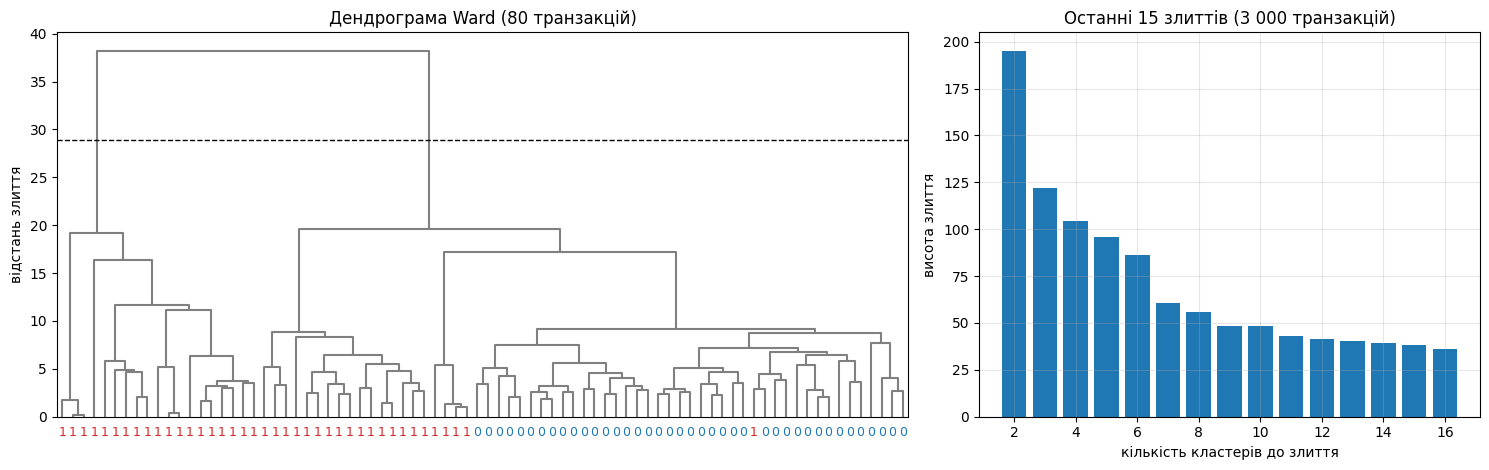

,поріг відстані,кластерів,ARI,accuracy,частка найбільшого
0,158.476,2,0.681,0.913,0.579
1,113.123,3,0.567,0.913,0.579
2,100.186,4,0.557,0.913,0.579
3,90.928,5,0.553,0.913,0.579
4,73.295,6,0.481,0.913,0.579
5,58.156,7,0.476,0.913,0.579


Відношення висоти останнього злиття до попереднього: 1.6


In [24]:
D80, y80 = draw(80, seed=1)
L80 = linkage(prep(V)(D80, None), "ward")
D3k, y3k = draw(3000, seed=0)
Z3k = prep(V)(D3k, None)
L3k = linkage(Z3k, "ward")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
dendrogram(L80, labels=y80.astype(int).astype(str), leaf_font_size=9, leaf_rotation=0, ax=ax[0], color_threshold=0, above_threshold_color="gray")
for tick in ax[0].get_xmajorticklabels():
    tick.set_color("tab:red" if tick.get_text() == "1" else "tab:blue")
ax[0].axhline((L80[-1, 2] + L80[-2, 2]) / 2, color="black", ls="--", lw=1)
ax[0].set_title("Дендрограма Ward (80 транзакцій)"); ax[0].set_ylabel("відстань злиття"); ax[0].grid(False)

heights = {k: L3k[-(k - 1), 2] for k in range(2, 17)}          # висота злиття, що зменшує кількість кластерів із k до k − 1
ax[1].bar(list(heights), list(heights.values()), color="tab:blue")
ax[1].set_xlabel("кількість кластерів до злиття"); ax[1].set_ylabel("висота злиття"); ax[1].set_title("Останні 15 злиттів (3 000 транзакцій)")
plt.tight_layout(); plt.show()

rows = []
for k in range(2, 8):
    t = (heights[k] + L3k[-k, 2]) / 2                           # поріг між злиттям k → k−1 та (k+1) → k
    lab = fcluster(L3k, t, criterion="distance")
    sc = cluster_scores(Z3k, lab, y3k)
    rows.append({"поріг відстані": t, "кластерів": len(np.unique(lab)), "ARI": sc["ARI"], "accuracy": sc["accuracy"], "частка найбільшого": sc["max_share"]})
display(pd.DataFrame(rows).round(3))
print("Відношення висоти останнього злиття до попереднього:", round(heights[2] / heights[3], 2))

**Висновок.** На дендрограмі 80 транзакцій верхній поділ відокремлює групу з 19 суто шахрайських транзакцій; решта (40 легальних і 21 шахрайська) далі ділиться так, що шахрайські групуються окремо від легальних (у правій гілці лишається лише один шахрайський листок). Для вибірки з 3 000 транзакцій остання висота злиття (≈ 195) помітно більша за попередню (≈ 122; відношення 1.6), тобто найбільший «стрибок» вказує на k = 2, що збігається з кількістю класів. Поріг відстані ≈ 158 дає два кластери з ARI 0.681 і accuracy 0.913, а зниження порога до 113 → 58 збільшує кількість кластерів до 3 → 7 і зменшує ARI до 0.567 → 0.476. Найбільший кластер (57.9% вибірки) не дробиться на всьому діапазоні k = 2…7, тож додаткові кластери відщеплюються від меншої групи.

### 7.10. Розмір вибірки та час роботи
k-середніх мають складність, лінійну за кількістю об'єктів, а ієрархічна кластеризація — квадратичну за часом і пам'яттю (матриця відстаней $n\times n$). Дивимось, як від розміру вибірки залежать ARI та час одного запуску; k-середніх запускаємо навіть на всіх 568 629 транзакціях.

k-середніх:


,ARI,± ARI,"час, с"
розмір вибірки,,,
100,0.5868,0.1413,0.0129
300,0.4995,0.0648,0.0162
1000,0.5805,0.0493,0.0263
3000,0.5916,0.0162,0.0558
10000,0.5741,0.0269,0.1300
30000,0.5779,0.0032,0.3211
100000,0.5850,0.0007,1.0264
568629,0.5844,0.0003,5.0969


Ward:


,ARI,± ARI,"час, с","матриця відстаней, МБ"
розмір вибірки,,,,
100,0.6455,0.1643,0.0009,0.0396
300,0.6609,0.1251,0.0029,0.3588
1000,0.5304,0.2260,0.0229,3.9960
3000,0.3183,0.3165,0.4126,35.9880
6000,0.4394,0.2872,1.6861,143.9760
12000,0.2805,0.2847,8.0860,575.9520


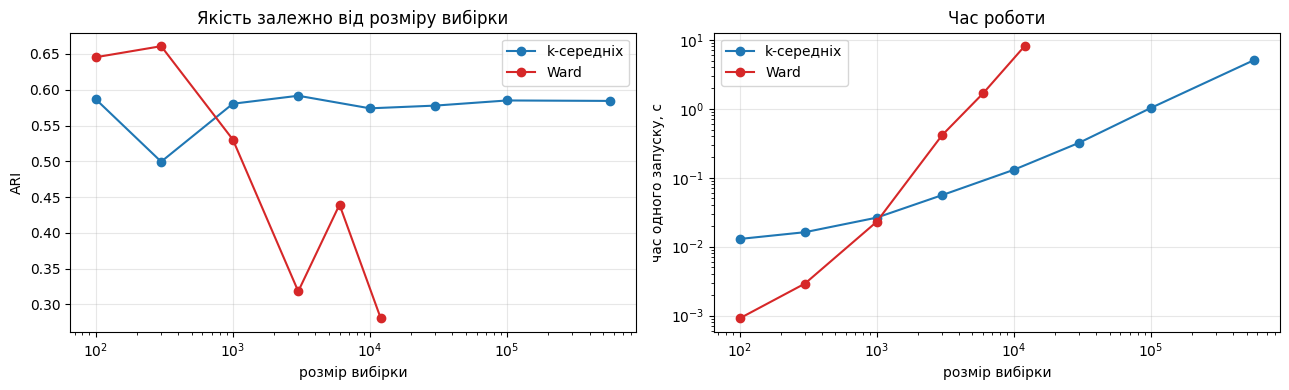

In [25]:
def size_curve(fit, sizes, repeats_for):
    rows = {}
    for n in sizes:
        runs = []
        for r in range(repeats_for(n)):
            D, yy = draw(n, seed=r)
            Z = prep(V)(D, None)
            t0 = time.perf_counter(); lab = fit(Z, 2, r); t = time.perf_counter() - t0
            runs.append({"ARI": adjusted_rand_score(yy, lab), "час, с": t})
        d_ = pd.DataFrame(runs)
        rows[n] = {"ARI": d_["ARI"].mean(), "± ARI": d_["ARI"].std(), "час, с": d_["час, с"].mean()}
    return pd.DataFrame(rows).T.rename_axis("розмір вибірки")

size_km = size_curve(ALGOS["k-середніх"], [100, 300, 1000, 3000, 10_000, 30_000, 100_000, len(data)], lambda n: 5 if n <= 30_000 else 3)
size_w = size_curve(ALGOS["Ward"], [100, 300, 1000, 3000, 6000, 12_000], lambda n: 5 if n <= 3000 else 3)
size_w["матриця відстаней, МБ"] = size_w.index * (size_w.index - 1) / 2 * 8 / 1e6
print("k-середніх:"); display(size_km.round(4))
print("Ward:");       display(size_w.round(4))
FACTORS["Розмір вибірки"] = pd.concat([size_km["ARI"].rename("k-середніх"), size_w["ARI"].rename("Ward")], axis=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for tbl, name, color in [(size_km, "k-середніх", "tab:blue"), (size_w, "Ward", "tab:red")]:
    ax[0].plot(tbl.index, tbl["ARI"], marker="o", color=color, label=name)
    ax[1].plot(tbl.index, tbl["час, с"], marker="o", color=color, label=name)
ax[0].set_xscale("log"); ax[0].set_xlabel("розмір вибірки"); ax[0].set_ylabel("ARI"); ax[0].set_title("Якість залежно від розміру вибірки"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("розмір вибірки"); ax[1].set_ylabel("час одного запуску, с"); ax[1].set_title("Час роботи"); ax[1].legend()
plt.tight_layout(); plt.show()

**Висновок.** k-середніх на вибірках ≥ 1 000 дають ARI 0.574–0.592, розкид між вибірками зменшується з 0.141 (n = 100) до 0.0003 (весь набір), а час зростає майже лінійно: приблизно від 0.01 с (n = 1 000) до 0.03–0.04 с (10 000), ≈ 0.3 с (100 000) і 2–3 с на всьому наборі (568 629). Ward масштабується приблизно квадратично: при кожному подвоєнні n від 3 000 до 12 000 час зростає у 4.5–6 разів (від ≈ 0.2 с до ≈ 6 с), а матриця відстаней при n = 12 000 займає 576 МБ (для всього набору було б ≈ 1.3 ТБ). ARI Ward зі збільшенням вибірки не стабілізується (0.65–0.66 при n = 100–300, далі 0.53, 0.32, 0.44, 0.28 із розкидом 0.23–0.32), тобто нестабільність при k = 2 не зникає з ростом n.

### 7.11. Зведення: які фактори впливають найсильніше
Для кожного фактора — розмах ARI (максимум мінус мінімум) серед перевірених варіантів, окремо для k-середніх та для ієрархічної кластеризації (Ward або, для типу зв'язку та метрики, відповідні варіанти). Чим більший розмах, тим чутливіша точність до цього фактора.

,k-середніх,ієрархічна
Викиди,0.022,0.209
Кількість кластерів k,0.270,0.261
Тип зв'язку (k = 2),NaN,0.318
Шумові ознаки,0.001,0.375
Розмір вибірки,0.092,0.380
Випадкова ініціалізація (n_init = 1),0.587,NaN
"Метрика відстані (average, k = 2)",NaN,0.636
Масштабування,0.588,0.689
Дисбаланс класів,0.847,0.858
Набір ознак,0.983,0.802


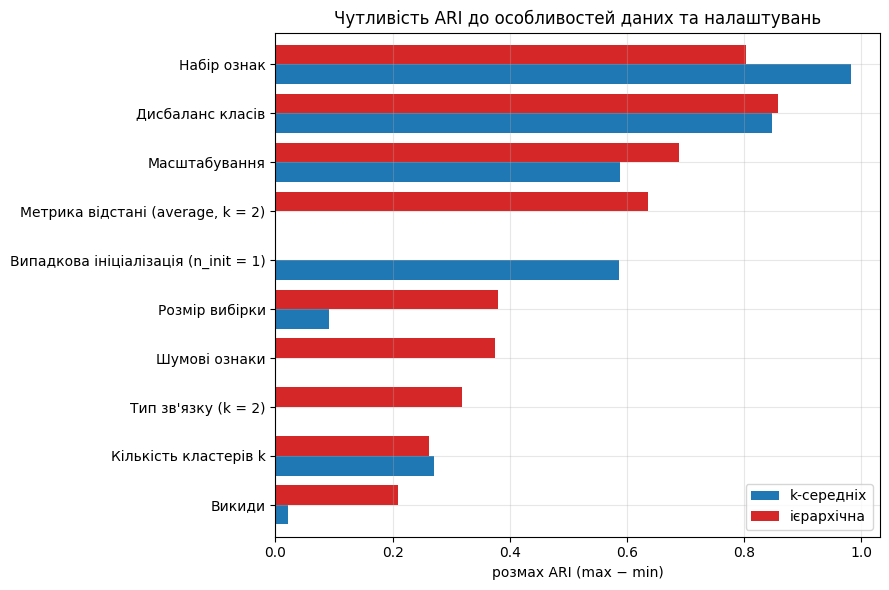

In [26]:
rows = {}
for name, df_ in FACTORS.items():
    hier = df_["Ward"] if "Ward" in df_ else df_["ієрархічна"] if "ієрархічна" in df_ else None
    km = df_["k-середніх"] if "k-середніх" in df_ else None
    rows[name] = {"k-середніх": km.max() - km.min() if km is not None else np.nan,
                  "ієрархічна": hier.max() - hier.min() if hier is not None else np.nan}
summary_df = pd.DataFrame(rows).T
summary_df = summary_df.loc[summary_df.max(axis=1).sort_values().index]
display(summary_df.round(3))

ax = summary_df.plot.barh(figsize=(9, 6), width=0.8, color=["tab:blue", "tab:red"])
ax.set_xlabel("розмах ARI (max − min)"); ax.set_title("Чутливість ARI до особливостей даних та налаштувань")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Висновок.** Найсильніше на точність впливають набір ознак (розмах ARI 0.98 у k-середніх, 0.80 у Ward; без артефакту `id` у k-середніх було б 0.69), дисбаланс класів (0.85 / 0.86) та масштабування (0.59 / 0.69). Для k-середніх з одним запуском додатково важлива ініціалізація (розмах 0.59 між 30 запусками). k-середніх майже нечутливі до викидів (0.02), шумових ознак (0.001) і розміру вибірки (0.09, головно через найменші вибірки), тоді як ієрархічна кластеризація чутлива до шуму (0.38), розміру вибірки (0.38), викидів (0.21), типу зв'язку (0.32) та метрики (0.64 для average). Розмах включає вироджені налаштування (ARI ≈ 0), тому він показує, наскільки сильно можна зіпсувати результат, а не типову чутливість.

## 8. Підсумкова модель на всьому датасеті
З урахуванням експериментів: ознаки — `V1`–`V28` (без `Amount` та `id`), стандартизація, `k = 2`. k-середніх (k-means++, 10 запусків) запускаємо на всіх 568 629 транзакціях. Ієрархічна кластеризація на всьому наборі неможлива (матриця відстаней була б порядку 1.3 ТБ), тому кластеризуємо випадкову підвибірку з 10 000 транзакцій, а решту відносимо до кластера з найближчим центром — типовий спосіб застосувати ієрархічну кластеризацію до великих даних. Беремо варіанти, що спрацювали в експериментах: Ward без обробки (для порівняння), Ward з обмеженням викидів `|z| ≤ 2` (7.4) та зв'язок average з косинусною відстанню (7.8). Для кожного варіанта повторюємо розрахунок на трьох різних підвибірках. Параметри підібрані за ARI, тобто з використанням міток, тому оцінка дещо оптимістична.

,ARI,NMI,accuracy,silhouette,precision,recall,SSE на об'єкт,"час, с"
k-середніх,0.5846,0.5765,0.8823,0.2870,0.9997,0.7648,20.4265,4.2692
Ward (підвибірка 10 000 + найближчий центр),0.1826,0.2920,0.7137,0.3359,0.9997,0.4275,20.8992,6.0026
"Ward, обмеження |z| ≤ 2 (підвибірка 10 000 + найближчий центр)",0.6503,0.6255,0.9032,0.2819,0.9997,0.8067,20.4609,4.9078
"average, косинусна відстань (підвибірка 10 000 + найближчий центр)",0.6561,0.6300,0.9050,0.2805,0.9997,0.8103,20.4678,4.9617


ARI на всьому наборі для трьох різних підвибірок (random_state 42, 0, 1):


,Ward,"Ward, обмеження |z| ≤ 2","average, косинусна відстань"
підвибірка 42,0.183,0.650,0.656
підвибірка 0,0.206,0.641,0.657
підвибірка 1,0.573,0.644,0.657


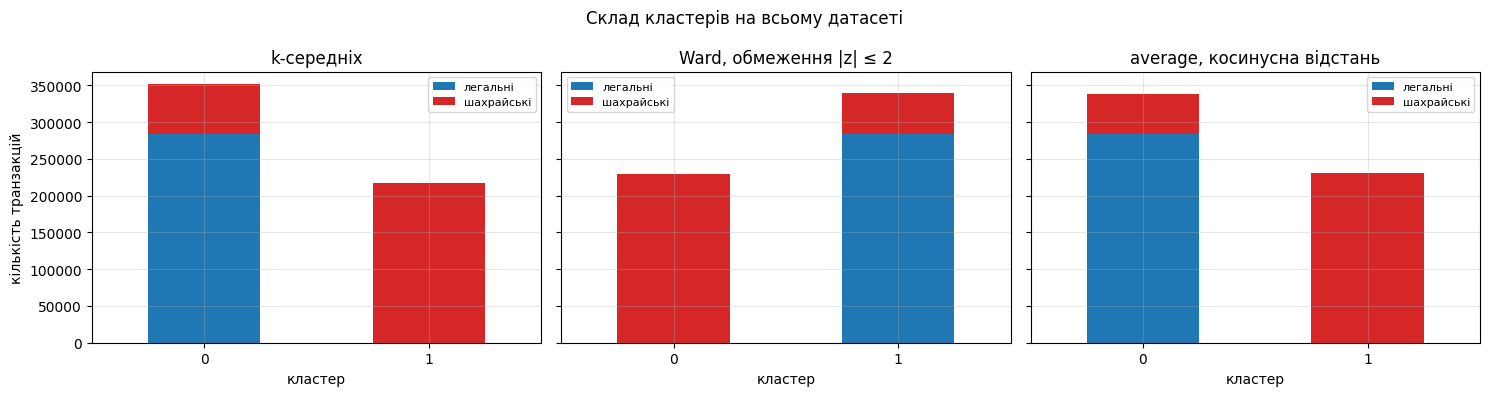

In [27]:
scaler = StandardScaler().fit(data[V])
Z_full = scaler.transform(data[V])

t0 = time.perf_counter()
km_full = KMeans(2, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(Z_full)
t_km = time.perf_counter() - t0

def hier_full(seed, link="ward", metric="euclidean", clip=None, n=10_000):
    """Ієрархічна кластеризація підвибірки з n об'єктів + призначення решти до найближчого центру."""
    D, _ = draw(n, seed)
    Zs, Zf = scaler.transform(D[V]), Z_full
    if clip:
        Zs, Zf = np.clip(Zs, -clip, clip), np.clip(Zf, -clip, clip)
    t0 = time.perf_counter()
    m = AgglomerativeClustering(2, linkage=link, metric=metric).fit(Zs)
    centers = np.array([Zs[m.labels_ == c].mean(axis=0) for c in range(2)])
    labels = cdist(Zf, centers, metric).argmin(axis=1)          # решту об'єктів — до найближчого центру
    return labels, time.perf_counter() - t0

HIER = {
    "Ward":                         dict(),
    "Ward, обмеження |z| ≤ 2":      dict(clip=2),
    "average, косинусна відстань":  dict(link="average", metric="cosine"),
}
SEEDS = [RANDOM_STATE, 0, 1]
runs = {name: [hier_full(s, **kw) for s in SEEDS] for name, kw in HIER.items()}

rows = {"k-середніх": {**cluster_scores(Z_full, km_full.labels_, y_all), "час, с": t_km}}
for name, rr in runs.items():
    rows[name + " (підвибірка 10 000 + найближчий центр)"] = {**cluster_scores(Z_full, rr[0][0], y_all), "час, с": rr[0][1]}
final = pd.DataFrame(rows).T
final["SSE на об'єкт"] = final["SSE"] / len(Z_full)
display(final[["ARI", "NMI", "accuracy", "silhouette", "precision", "recall", "SSE на об'єкт", "час, с"]].round(4))

print("ARI на всьому наборі для трьох різних підвибірок (random_state 42, 0, 1):")
display(pd.DataFrame({name: [adjusted_rand_score(y_all, lab) for lab, _ in rr] for name, rr in runs.items()}, index=[f"підвибірка {s}" for s in SEEDS]).round(3))

best_name = "average, косинусна відстань"
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (name, lab) in zip(ax, [("k-середніх", km_full.labels_), ("Ward, обмеження |z| ≤ 2", runs["Ward, обмеження |z| ≤ 2"][0][0]), (best_name, runs[best_name][0][0])]):
    pd.crosstab(lab, y_all).rename(columns={0: "легальні", 1: "шахрайські"}).plot.bar(stacked=True, ax=a, rot=0, color=["tab:blue", "tab:red"])
    a.set_xlabel("кластер"); a.set_title(name); a.legend(fontsize=8)
ax[0].set_ylabel("кількість транзакцій")
plt.suptitle("Склад кластерів на всьому датасеті"); plt.tight_layout(); plt.show()

**Висновок.** На всьому наборі (568 629 транзакцій) k-середніх дають ARI 0.585, NMI 0.577, accuracy 0.882, силует 0.287 за 2–3 с, що збігається з результатами на вибірках (0.58–0.59). Ward без обробки на підвибірці з 10 000 нестабільний: ARI 0.183, 0.206 та 0.573 на трьох підвибірках. Ward з обмеженням |z| ≤ 2 дає стабільні 0.650 / 0.641 / 0.644, а average з косинусною відстанню — 0.656 / 0.657 / 0.657, тобто найкращий і найстабільніший варіант: recall шахрайського кластера 0.810 проти 0.765 у k-середніх при тій самій precision (0.9997). SSE на об'єкт майже однаковий (20.43 у k-середніх, 20.46 і 20.47 у кращих ієрархічних варіантів), хоча k-середніх мінімізують його найкраще, а силует найвищий у найгіршого варіанта (Ward без обробки, 0.336). У всіх варіантів один кластер майже чисто шахрайський (≈ 217–230 тис. транзакцій), а інший містить усі легальні та 19–24% шахрайських, які в цих ознаках не відрізнити від легальних. Параметри підбиралися за ARI, тобто з використанням міток, тому оцінка дещо оптимістична.

## 9. Порівняння методів
Порівнюємо методи кластеризації на однакових вибірках (5 вибірок по 5 000 транзакцій, ознаки V1–V28, стандартизація, `k = 2`): k-середніх, k-медіан (власна реалізація), ієрархічну кластеризацію зі зв'язком Ward, а також зв'язки average, complete та single (евклідова відстань) і average з косинусною відстанню — найкращий варіант із 7.8.

,ARI,± ARI,NMI,accuracy,silhouette,частка найбільшого,"час, с"
k-середніх,0.5583,0.0242,0.5579,0.8736,0.2961,0.6263,0.3257
k-медіан (власна),0.6172,0.0160,0.6003,0.8928,0.2911,0.6069,0.4758
Ward,0.2231,0.2411,0.3113,0.7165,0.3504,0.7828,1.2370
"average, косинусна відстань",0.6456,0.0302,0.6046,0.9017,0.2786,0.5915,1.3546
"complete, евклідова",0.0002,0.0003,0.0084,0.5047,0.6315,0.9952,1.1650
"single, евклідова",0.0000,0.0000,0.0004,0.5002,0.7358,0.9998,0.5879


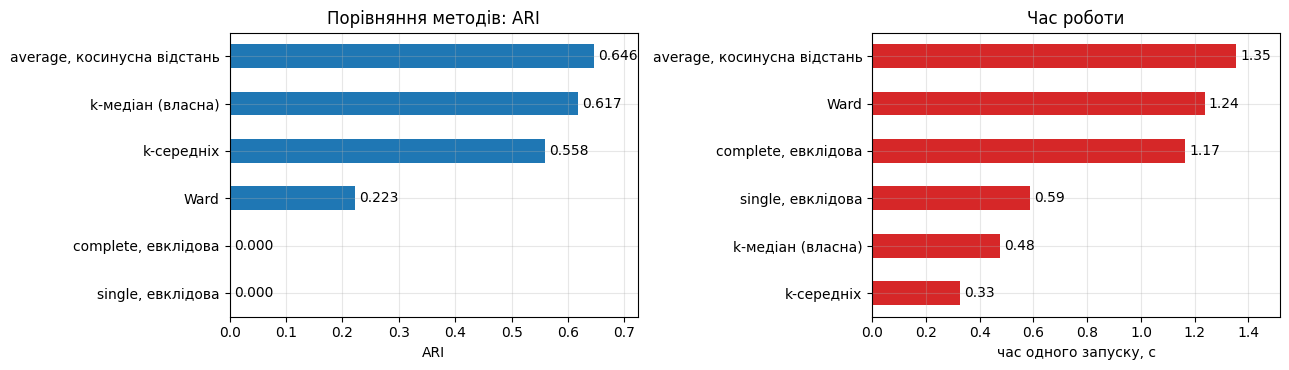

In [28]:
CMP = {
    "k-середніх":                  (prep(V),          ALGOS["k-середніх"]),
    "k-медіан (власна)":           (prep(V),          OUT_ALGOS["k-медіан"]),
    "Ward":                        (prep(V),          ALGOS["Ward"]),
    "average, косинусна відстань": (prep(V),          agg("average", "cosine")),
    "complete, евклідова":         (prep(V),          agg("complete")),
    "single, евклідова":           (prep(V),          agg("single")),
}
cmp_rows = {}
for name, (p, fit) in CMP.items():
    st = evaluate(p, n=5000, algos={name: fit}, repeats=5)[name]
    cmp_rows[name] = {"ARI": st.loc["mean", "ARI"], "± ARI": st.loc["std", "ARI"], "NMI": st.loc["mean", "NMI"],
                      "accuracy": st.loc["mean", "accuracy"], "silhouette": st.loc["mean", "silhouette"],
                      "частка найбільшого": st.loc["mean", "max_share"], "час, с": st.loc["mean", "time"]}
comparison = pd.DataFrame(cmp_rows).T
display(comparison.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
comparison["ARI"].sort_values().plot.barh(ax=ax[0], color="tab:blue"); ax[0].set_xlabel("ARI"); ax[0].set_title("Порівняння методів: ARI")
ax[0].bar_label(ax[0].containers[0], fmt="%.3f", padding=3); ax[0].margins(x=0.12)
comparison["час, с"].sort_values().plot.barh(ax=ax[1], color="tab:red"); ax[1].set_xlabel("час одного запуску, с"); ax[1].set_title("Час роботи")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f", padding=3); ax[1].margins(x=0.12)
plt.tight_layout(); plt.show()

**Висновок.** На вибірках по 5 000 транзакцій найкращі за ARI — average з косинусною відстанню (0.646 ± 0.030) і k-медіан (0.617 ± 0.016), далі k-середніх (0.558 ± 0.024); різниця між першими двома в межах розкиду. Ward без обробки викидів нестабільний (0.223 ± 0.241), а complete та single в евклідовій метриці дають ARI ≈ 0 (частка найбільшого кластера 0.995 і 0.9998). Силует найвищий саме для цих вироджених розбиттів (0.74 для single і 0.63 для complete проти 0.28–0.30 у робочих методів), тому як єдиний критерій вибору методу він непридатний. Найшвидший метод — k-середніх (≈ 0.1 с на вибірці з 5 000), k-медіан у ≈ 3 рази повільніший, а ієрархічні (Ward, average, complete) — у ≈ 6–8 разів, і для більших даних розрив зростає (п. 7.10).

## 10. Переваги та недоліки методів
**k-середніх**

*Переваги:*
- Швидкий і добре масштабується: 2–3 с на 568 629 транзакцій, час росте майже лінійно від n.
- Простий у реалізації (власна версія збігається зі `sklearn`), дає центри кластерів, а нові об'єкти легко віднести до найближчого центру.
- Стабільний між вибірками (розкид ARI ≈ 0.02) і в наших експериментах майже нечутливий до шумових ознак та викидів.

*Недоліки:*
- Потрібно заздалегідь задати k (тут k = 2 вдалося знайти за силуетом, але «лікоть» на SSE відсутній).
- Залежить від початкових центрів: при одному запуску ARI коливався від 0.00 до 0.59, тому потрібні k-means++ та кілька запусків (`n_init ≥ 10`).
- Дуже чутливий до масштабування та складу ознак: без стандартизації ARI ≈ 0, а артефакт на кшталт `id` створює хибну «точність» 0.98.
- Шукає компактні кластери однакового розміру: шахрайські транзакції утворюють розтягнуту хмару, тому 19–24% з них потрапляє до «легального» кластера; при частці шахрайства ≤ 1% кластери перестають відповідати класам.

**Ієрархічна кластеризація**

*Переваги:*
- Не потребує k заздалегідь: дендрограма й поріг відстані (стрибок висоти) вказали на k = 2.
- Гнучкість у виборі зв'язку та метрики: average з косинусною відстанню дав найкращий ARI (0.646–0.657).
- Детермінована: не залежить від початкових центрів.

*Недоліки:*
- Квадратичні вимоги до пам'яті та часу (12 000 об'єктів — 576 МБ і ≈ 6 с, весь набір — ≈ 1.3 ТБ), тому на великих даних потрібні підвибірка й дозавантаження решти за найближчим центром.
- Сильно залежить від зв'язку, метрики та викидів: complete, average і single з евклідовою відстанню дали ARI ≈ 0, відколюючи поодинокі викиди.
- Ward при k = 2 нестабільний (ARI від 0.08 до 0.80 між вибірками) і чутливий до шумових ознак (0.80 → 0.43 при 100 шумових ознаках).
- Злиття незворотні: помилковий ранній поділ уже не виправляється.

## 11. Загальні висновки
- Реалізовано власні алгоритми k-середніх (з варіантом k-медіан) та агломеративної кластеризації (single, complete, average, ward); вони збігаються з `sklearn` і `scipy`, а на датасеті Credit Card Fraud Detection 2023 (568 629 транзакцій) їх «точність» оцінено за ARI відносно мітки `Class`.
- Класи в цих ознаках розділяються лише частково: k-середніх на всьому наборі дають ARI 0.585, а найкращий ієрархічний варіант (average з косинусною відстанню на підвибірці з 10 000 + призначення решти) — 0.656. Один кластер майже чисто шахрайський, але 19–24% шахрайських транзакцій схожі на легальні.
- Точність найбільше залежить від параметрів даних: масштабування (без нього ARI ≈ 0, а RobustScaler на важкохвостих ознаках теж дає ≈ 0), складу ознак (`Amount` і 10 найслабших `V` не несуть структури, п'ять найкращих `V` дають 0.69 / 0.80) та частки шахрайства (при ≤ 1% кластери перестають відповідати класам).
- k-середніх стабільні й нечутливі до шуму, викидів та розміру вибірки, але залежать від ініціалізації (потрібні k-means++ і `n_init ≥ 10`). Ієрархічна кластеризація чутлива до шуму, викидів, зв'язку та метрики; Ward при k = 2 нестабільний, а на великих даних потребує підвибірки.
- Внутрішній критерій (силует) тут ненадійний: він вищий для безглуздих розбиттів (без масштабування, single/complete, RobustScaler) і падає від шумових ознак, не змінюючи відповідності класам. Його можна використовувати для вибору k за однакового набору ознак, але не для порівняння методів чи наборів ознак.
- Датасет має артефакти: колонка `id` впорядкована за класом (k-середніх за нею одною дають ARI 0.98), а `Amount` від класу не залежить; класи збалансовані 50 / 50, тоді як у реальних даних шахрайство значно рідкісніше, тож результати оптимістичні.
- Практичні рекомендації: стандартизувати ознаки, відібрати інформативні та прибрати службові колонки, використовувати k-means++ з кількома запусками, для ієрархічної кластеризації брати підвибірку й підбирати зв'язок та метрику (косинусна відстань або обмеження викидів).